# EDA - Data Pembelian Frozen Food (April - September 2020)

In [1]:
import re
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import matplotlib.dates as mdates
from matplotlib.colors import LinearSegmentedColormap
import seaborn as sns

CAT = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#4a3aa7', '#e34948']
SEQ_BLUE = LinearSegmentedColormap.from_list(
    'seq_blue', ['#cde2fb', '#9ec5f4', '#6da7ec', '#3987e5', '#256abf', '#184f95', '#0d366b']
)
ORDINAL_BLUE = ['#184f95', '#3987e5', '#86b6ef']
POS, NEG = '#2a78d6', '#e34948'
INK, INK_SECOND, INK_MUTED = '#0b0b0b', '#52514e', '#898781'
GRID, BASELINE, SURFACE = '#e1e0d9', '#c3c2b7', '#fcfcfb'
C_RP, C_QTY, C_CNT, C_AVG, C_DISC = CAT[0], CAT[1], CAT[2], CAT[6], CAT[4]

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': BASELINE,
    'axes.labelcolor': INK_SECOND, 'axes.titlecolor': INK, 'text.color': INK,
    'xtick.color': INK_MUTED, 'ytick.color': INK_MUTED, 'grid.color': GRID,
    'axes.grid': True, 'axes.grid.axis': 'y',
    'axes.spines.top': False, 'axes.spines.right': False,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlepad': 12,
    'font.size': 11, 'figure.dpi': 100, 'legend.frameon': False,
})

RP_JT = mticker.FuncFormatter(lambda x, _: f'{x/1e6:,.0f} Jt')
RP_JT1 = mticker.FuncFormatter(lambda x, _: f'{x/1e6:,.1f} Jt')
RP_RB = mticker.FuncFormatter(lambda x, _: f'{x/1e3:,.0f} Rb')
PCT = mticker.PercentFormatter(1.0, decimals=0)


def short(s, n=34):
    s = str(s)
    return s if len(s) <= n else s[:n - 1] + '…'


def xgrid(ax):
    ax.grid(False)
    ax.grid(axis='x', visible=True)


def label_bars(ax, bars, fmt, horizontal=False):
    for b in bars:
        if horizontal:
            v = b.get_width()
            ax.text(v, b.get_y() + b.get_height() / 2, ' ' + fmt(v), va='center', fontsize=9, color=INK_SECOND)
        else:
            v = b.get_height()
            ax.text(b.get_x() + b.get_width() / 2, v, fmt(v), ha='center', va='bottom', fontsize=9, color=INK_SECOND)


def barh_top(s, title, xlabel, color, fmt=None, figsize=(10, 7), ax=None, label_len=40):
    own = ax is None
    if own:
        fig, ax = plt.subplots(figsize=figsize)
    y = np.arange(len(s))
    ax.barh(y, s.values[::-1], color=color, height=0.7)
    ax.set_yticks(y, [short(i, label_len) for i in s.index[::-1]])
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    if fmt is not None:
        ax.xaxis.set_major_formatter(fmt)
    xgrid(ax)
    if own:
        plt.tight_layout()
        plt.show()


def styled_boxplot(ax, groups, labels, color=CAT[0], horizontal=False):
    bp = ax.boxplot(
        groups, tick_labels=labels, patch_artist=True, widths=0.6,
        orientation='horizontal' if horizontal else 'vertical',
        flierprops=dict(marker='o', markersize=3, markerfacecolor=INK_MUTED, markeredgecolor='none', alpha=0.5),
        medianprops=dict(color=INK, linewidth=1.5),
        whiskerprops=dict(color=INK_MUTED), capprops=dict(color=INK_MUTED),
    )
    for p in bp['boxes']:
        p.set_facecolor(color)
        p.set_alpha(0.55)
        p.set_edgecolor(INK_MUTED)
    return bp


def share_stacked(col, title, top_n=7):
    top = df.groupby(col)['JUMLAH'].sum().drop('Lainnya', errors='ignore').nlargest(top_n).index.tolist()
    grp = df[col].where(df[col].isin(top), 'Lainnya')
    tbl = (df.assign(_G=grp)
             .pivot_table(index='BULAN', columns='_G', values='JUMLAH', aggfunc='sum', observed=False)
             .fillna(0))
    tbl = tbl[top + (['Lainnya'] if 'Lainnya' in tbl.columns else [])]
    share = tbl.div(tbl.sum(axis=1), axis=0)
    colors = CAT[:len(top)] + [BASELINE]
    fig, ax = plt.subplots(figsize=(12, 6))
    bottom = np.zeros(len(share))
    for c, color in zip(share.columns, colors):
        ax.bar(share.index.astype(str), share[c].values, bottom=bottom, color=color, label=c,
               width=0.65, edgecolor=SURFACE, linewidth=1.5)
        bottom += share[c].values
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(PCT)
    ax.set_title(title)
    h, l = ax.get_legend_handles_labels()
    ax.legend(h[::-1], l[::-1], bbox_to_anchor=(1.01, 1), loc='upper left')
    plt.tight_layout()
    plt.show()


def small_multiples(col, items, title, color=C_RP, ncols=4):
    nrows = int(np.ceil(len(items) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(4.2 * ncols, 3.2 * nrows))
    tbl = (df[df[col].isin(items)]
             .pivot_table(index='BULAN', columns=col, values='JUMLAH', aggfunc='sum', observed=False)
             .fillna(0))
    x = np.arange(len(MONTH_ORDER))
    for ax, it in zip(axes.flat, items):
        ax.plot(x, tbl[it].values, color=color, linewidth=2, marker='o', markersize=6)
        ax.fill_between(x, tbl[it].values, color=color, alpha=0.1)
        ax.set_title(short(it, 30), fontsize=11)
        ax.yaxis.set_major_formatter(RP_JT)
        ax.set_ylim(bottom=0)
        ax.set_xticks(x, [m[:3] for m in MONTH_ORDER])
    for ax in list(axes.flat)[len(items):]:
        ax.axis('off')
    fig.suptitle(title, fontsize=14, fontweight='bold')
    plt.tight_layout()
    plt.show()

## 1. Load & Gabungkan Data

In [2]:
FILES = {
    'april 2020.xlsx': 'April',
    'mei 2020.xlsx': 'Mei',
    'juni 2020.xlsx': 'Juni',
    'juli 2020.xlsx': 'Juli',
    'agustus 2020.xlsx': 'Agustus',
    'sep 2020.xlsx': 'September',
}
MONTH_ORDER = list(FILES.values())

def find_main_sheet(xls):
    for s in xls.sheet_names:
        raw = pd.read_excel(xls, sheet_name=s, header=None, nrows=5)
        if raw.shape[0] > 3 and str(raw.iloc[3, 0]).strip() == 'TGL':
            return s
    raise ValueError('Sheet transaksi utama tidak ditemukan')

frames = []
for fname, bulan in FILES.items():
    xls = pd.ExcelFile(fname)
    sheet = find_main_sheet(xls)
    d = pd.read_excel(xls, sheet_name=sheet, header=3)
    d['BULAN'] = bulan
    frames.append(d)

df = pd.concat(frames, ignore_index=True)
df.shape

(6784, 9)

## 2. Pembersihan & Feature Engineering

In [3]:
baris_awal = len(df)
df = df.dropna(subset=['TGL', 'KODEBARA']).copy()
baris_footer = baris_awal - len(df)

df['TGL'] = pd.to_datetime(df['TGL'])
df[['QTY', 'HARGA', 'JUMLAH']] = df[['QTY', 'HARGA', 'JUMLAH']].apply(pd.to_numeric, errors='coerce')
df = df.dropna(subset=['QTY', 'HARGA', 'JUMLAH'])

kode_tidak_standar = df['KODEBARA'].str.contains(r'\s').sum()
df['KODEBARA'] = df['KODEBARA'].str.replace(r'\s+', '', regex=True).str.upper()
df['NAMABARA'] = df['NAMABARA'].str.strip()
df['NAMA'] = df['NAMA'].str.strip()
df['SATUAN'] = df['SATUAN'].str.strip().replace({'PAC': 'PACK', 'BALL': 'BAL'})
df['PRODUK'] = df['KODEBARA'].map(df.groupby('KODEBARA')['NAMABARA'].agg(lambda s: s.mode().iat[0]))

HARI_ORDER = ['Senin', 'Selasa', 'Rabu', 'Kamis', 'Jumat', 'Sabtu', 'Minggu']
df['BULAN'] = pd.Categorical(df['BULAN'], categories=MONTH_ORDER, ordered=True)
df['BULAN_NO'] = df['BULAN'].cat.codes
df['HARI'] = pd.Categorical(df['TGL'].dt.dayofweek.map(dict(enumerate(HARI_ORDER))), categories=HARI_ORDER, ordered=True)
df['MINGGU'] = df['TGL'].dt.to_period('W').dt.start_time
df['BRAND'] = df['KODEBARA'].str.split('-').str[0]
df['CHANNEL'] = df['NAMA'].str.extract(r'^([A-Za-z]+)\s*-\s')[0].fillna('LAINNYA')
df['NOTA'] = df['TGL'].dt.strftime('%Y-%m-%d') + ' | ' + df['NAMA']
df['BRUTO'] = df['QTY'] * df['HARGA']
df['DISKON'] = df['BRUTO'] - df['JUMLAH']
df['GRATIS'] = df['HARGA'] == 0

df.shape

(6778, 19)

In [4]:
KATEGORI = [
    ('Es Krim', r'ES ?KRIM|\bLTR\b|\bCONE\b|NEAPOLITAN'),
    ('Kentang', r'SHOESTRING|FRIES|CRINKLE|WEDGE|POTATO|KENTANG|STEAKHOUSE|HASH ?BROWN'),
    ('Nugget', r'NUGGET|NUGET'),
    ('Sosis', r'SOSIS|SAUSAGE|FRANKFURT|BRATW|CHIPOLATA|KANZLER|COCKTAIL'),
    ('Bakso', r'BAKSO|\bBASO\b|MEATBALL'),
    ('Dimsum & Pao', r'DIMSUM|SIOMAY|HAKAU|HAKAO|\bPAO\b|DUMPLING|LUMPIA|GYOZA|MANTAO|WONTON|SAMOSA|SHUMAI'),
    ('Olahan Ikan & Seafood', r'OTAK|CHIKUWA|FISH|IKAN|SEAFOOD|NAGA|TEMPURA|UDANG|SHRIMP|CRAB|KEPITING|LOBSTER|SCALLOP|EKADO|CUMI|SALMON|TUNA|DORI|EMPEK'),
    ('Saus, Keju & Bumbu', r'SAUS|SAUCE|MAYO|CHILI|TOMAT|KECAP|PASTE|DRESSING|MUSTARD|KEJU|CHEESE|MOZZARELLA|MARGARIN|BUTTER|DELMONTE|MAESTRO'),
    ('Camilan', r'STICK|CIRENG|TAHU|BATAGOR|CHIPS|DONUT|DONAT|RISOL|CIMOL|TORTIL|SINGKONG|ROTI|PISANG|CHOCO|COKLAT|MOCHI|KEBAB|PIZZA|ROLL|DEN BAGUS|\bKEI\b'),
    ('Olahan Ayam & Daging', r'BURGER|BEEF|SMOKED|DAGING|KORNET|AYAM|CHICKEN|WING|KARAAGE|STEAK|SAPI|ROLADE|KATSU'),
]

def kategori(nama):
    nama = str(nama).upper()
    for kat, pola in KATEGORI:
        if re.search(pola, nama):
            return kat
    return 'Lainnya'

df['KATEGORI'] = df['PRODUK'].map(kategori)
df['KATEGORI'].value_counts()

KATEGORI
Olahan Ikan & Seafood    1003
Sosis                     970
Nugget                    955
Camilan                   929
Bakso                     816
Kentang                   594
Es Krim                   584
Dimsum & Pao              389
Olahan Ayam & Daging      234
Lainnya                   161
Saus, Keju & Bumbu        143
Name: count, dtype: int64

## 3. Kualitas Data

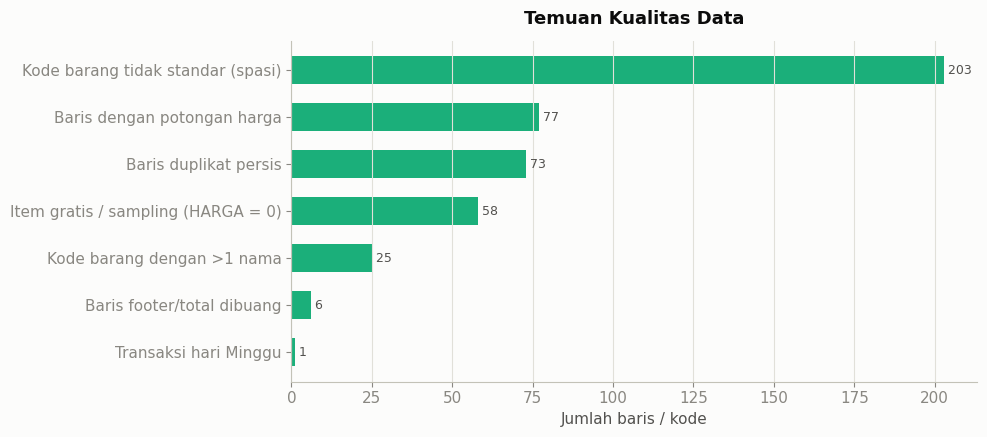

In [5]:
kualitas = pd.Series({
    'Baris footer/total dibuang': baris_footer,
    'Kode barang tidak standar (spasi)': kode_tidak_standar,
    'Baris duplikat persis': df.duplicated().sum(),
    'Item gratis / sampling (HARGA = 0)': df['GRATIS'].sum(),
    'Baris dengan potongan harga': (df['DISKON'] > 0).sum(),
    'Transaksi hari Minggu': (df['HARI'] == 'Minggu').sum(),
    'Kode barang dengan >1 nama': (df.groupby('KODEBARA')['NAMABARA'].nunique() > 1).sum(),
}).sort_values(ascending=False)

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.barh(kualitas.index[::-1], kualitas.values[::-1], color=C_CNT, height=0.6)
label_bars(ax, bars, lambda v: f'{v:,.0f}', horizontal=True)
ax.set_title('Temuan Kualitas Data')
ax.set_xlabel('Jumlah baris / kode')
xgrid(ax)
plt.tight_layout()
plt.show()

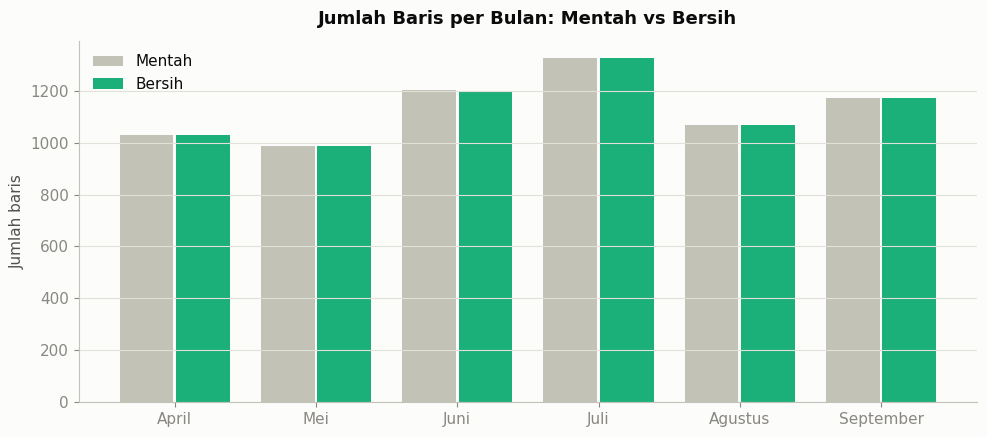

In [6]:
baris_per_file = pd.Series({b: len(f) for b, f in zip(MONTH_ORDER, frames)})
baris_bersih = df.groupby('BULAN', observed=False).size()

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(MONTH_ORDER))
ax.bar(x - 0.2, baris_per_file.values, width=0.38, color=BASELINE, label='Mentah')
ax.bar(x + 0.2, baris_bersih.values, width=0.38, color=C_CNT, label='Bersih')
ax.set_xticks(x, MONTH_ORDER)
ax.set_title('Jumlah Baris per Bulan: Mentah vs Bersih')
ax.set_ylabel('Jumlah baris')
ax.legend()
plt.tight_layout()
plt.show()

## 4. Ringkasan Data

In [7]:
df.info()
print('\nRentang tanggal:', df['TGL'].min().date(), '-', df['TGL'].max().date())

<class 'pandas.core.frame.DataFrame'>
Index: 6778 entries, 0 to 6782
Data columns (total 20 columns):
 #   Column    Non-Null Count  Dtype         
---  ------    --------------  -----         
 0   TGL       6778 non-null   datetime64[ns]
 1   KODEBARA  6778 non-null   object        
 2   NAMABARA  6778 non-null   object        
 3   QTY       6778 non-null   int64         
 4   SATUAN    6778 non-null   object        
 5   HARGA     6778 non-null   int64         
 6   JUMLAH    6778 non-null   int64         
 7   NAMA      6778 non-null   object        
 8   BULAN     6778 non-null   category      
 9   PRODUK    6778 non-null   object        
 10  BULAN_NO  6778 non-null   int8          
 11  HARI      6778 non-null   category      
 12  MINGGU    6778 non-null   datetime64[ns]
 13  BRAND     6778 non-null   object        
 14  CHANNEL   6778 non-null   object        
 15  NOTA      6778 non-null   object        
 16  BRUTO     6778 non-null   int64         
 17  DISKON    6778 non-

In [8]:
df[['QTY', 'HARGA', 'JUMLAH', 'BRUTO', 'DISKON']].describe().style.format('{:,.0f}')

,QTY,HARGA,JUMLAH,BRUTO,DISKON
count,"6,778","6,778","6,778","6,778","6,778"
mean,7,"150,972","668,388","669,042",655
std,14,"148,145","1,929,097","1,929,417","9,244"
min,1,0,0,0,0
25%,1,"18,000","115,000","115,000",0
50%,3,"130,000","240,000","240,000",0
75%,7,"240,000","552,000","552,000",0
max,400,"2,568,000","63,200,000","63,200,000","390,150"


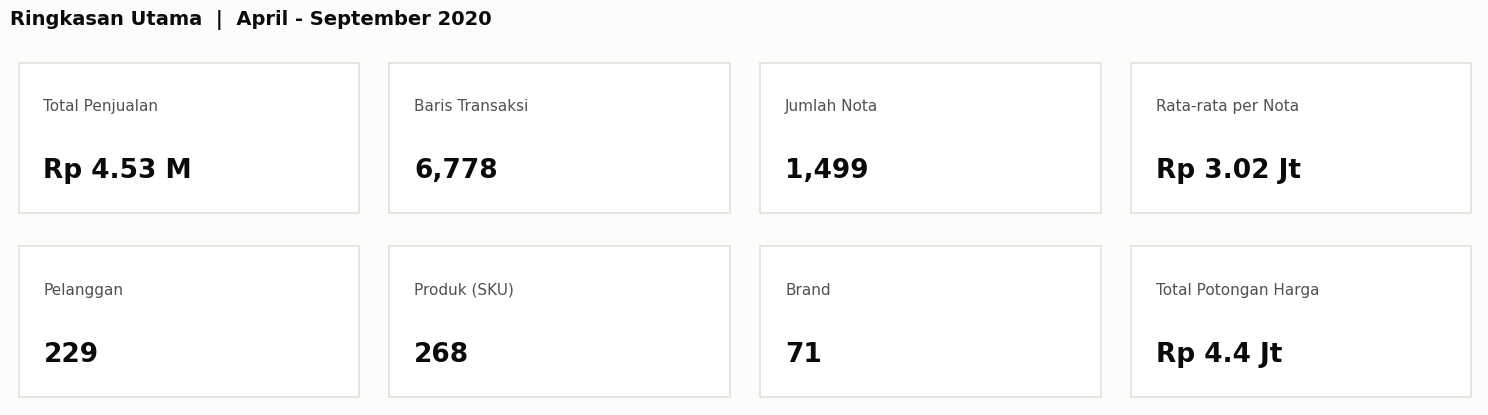

In [9]:
nilai_nota = df.groupby('NOTA')['JUMLAH'].sum()
kpi = {
    'Total Penjualan': f"Rp {df['JUMLAH'].sum()/1e9:,.2f} M",
    'Baris Transaksi': f"{len(df):,}",
    'Jumlah Nota': f"{df['NOTA'].nunique():,}",
    'Rata-rata per Nota': f"Rp {nilai_nota.mean()/1e6:,.2f} Jt",
    'Pelanggan': f"{df['NAMA'].nunique():,}",
    'Produk (SKU)': f"{df['KODEBARA'].nunique():,}",
    'Brand': f"{df['BRAND'].nunique():,}",
    'Total Potongan Harga': f"Rp {df['DISKON'].sum()/1e6:,.1f} Jt",
}

fig, axes = plt.subplots(2, 4, figsize=(15, 4.2))
for ax, (label, val) in zip(axes.flat, kpi.items()):
    ax.axis('off')
    ax.add_patch(plt.Rectangle((0.02, 0.05), 0.96, 0.9, transform=ax.transAxes,
                               facecolor='white', edgecolor=GRID, linewidth=1.2))
    ax.text(0.09, 0.66, label, fontsize=11, color=INK_SECOND, transform=ax.transAxes)
    ax.text(0.09, 0.26, val, fontsize=19, fontweight='bold', color=INK, transform=ax.transAxes)
fig.suptitle('Ringkasan Utama  |  April - September 2020', x=0.01, ha='left', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 5. Tren Penjualan

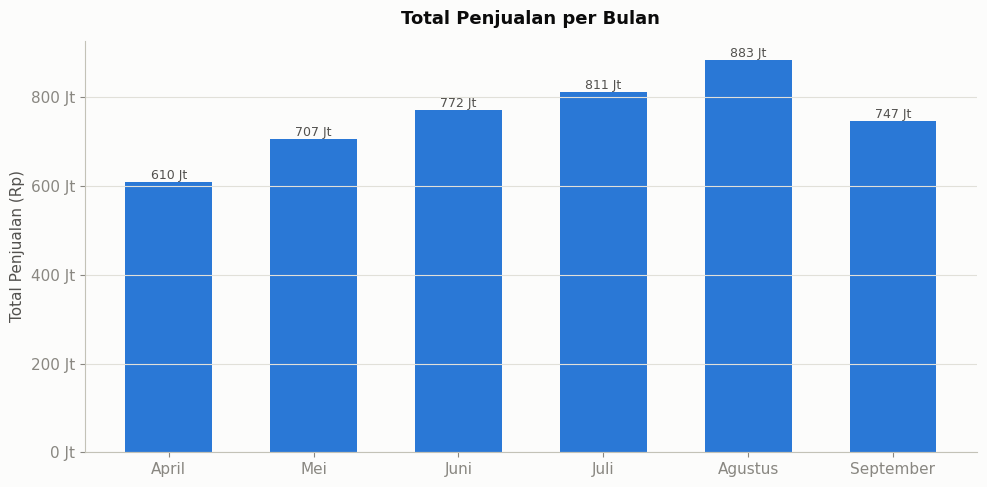

In [10]:
monthly = df.groupby('BULAN', observed=False)['JUMLAH'].sum()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(monthly.index.astype(str), monthly.values, color=C_RP, width=0.6)
label_bars(ax, bars, lambda v: f'{v/1e6:,.0f} Jt')
ax.set_title('Total Penjualan per Bulan')
ax.set_ylabel('Total Penjualan (Rp)')
ax.yaxis.set_major_formatter(RP_JT)
plt.tight_layout()
plt.show()

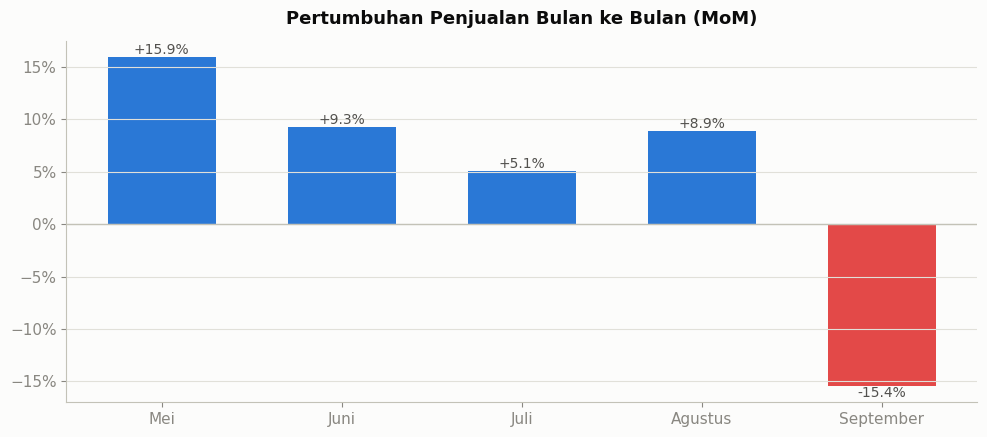

In [11]:
growth = monthly.pct_change().dropna()

fig, ax = plt.subplots(figsize=(10, 4.5))
bars = ax.bar(growth.index.astype(str), growth.values, width=0.6,
              color=[POS if v >= 0 else NEG for v in growth.values])
ax.axhline(0, color=BASELINE, linewidth=1)
for b, v in zip(bars, growth.values):
    ax.text(b.get_x() + b.get_width() / 2, v, f'{v:+.1%}', ha='center',
            va='bottom' if v >= 0 else 'top', fontsize=10, color=INK_SECOND)
ax.yaxis.set_major_formatter(PCT)
ax.set_title('Pertumbuhan Penjualan Bulan ke Bulan (MoM)')
plt.tight_layout()
plt.show()

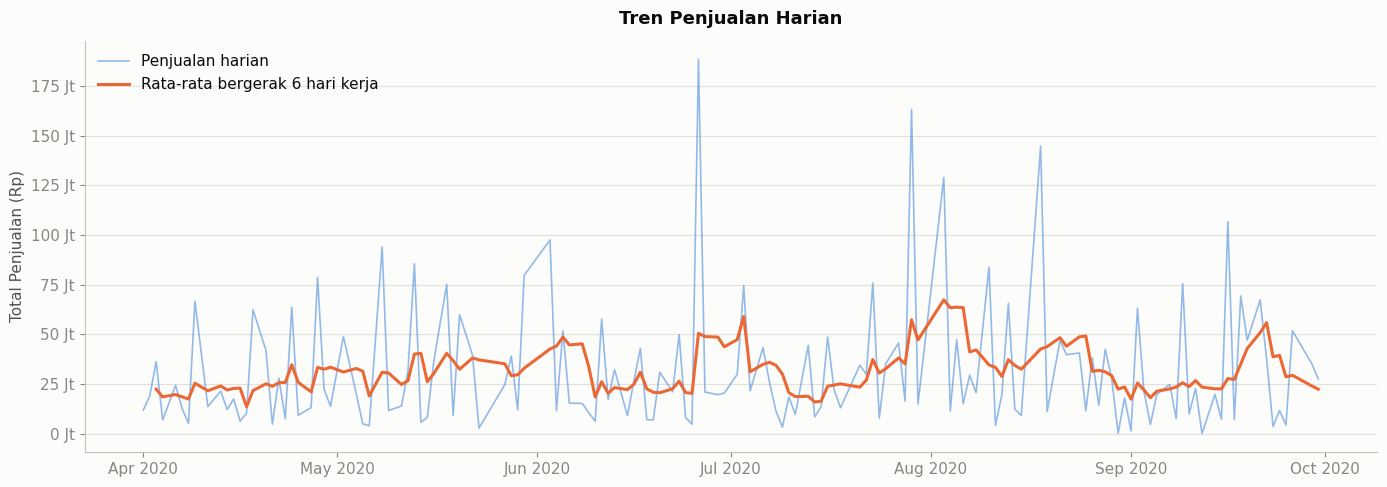

In [12]:
daily = df.groupby('TGL')['JUMLAH'].sum()
roll = daily.rolling(6, min_periods=3).mean()

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(daily.index, daily.values, color=C_RP, linewidth=1.2, alpha=0.5, label='Penjualan harian')
ax.plot(roll.index, roll.values, color=CAT[1], linewidth=2.2, label='Rata-rata bergerak 6 hari kerja')
ax.set_title('Tren Penjualan Harian')
ax.set_ylabel('Total Penjualan (Rp)')
ax.yaxis.set_major_formatter(RP_JT)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
ax.legend(loc='upper left')
plt.tight_layout()
plt.show()

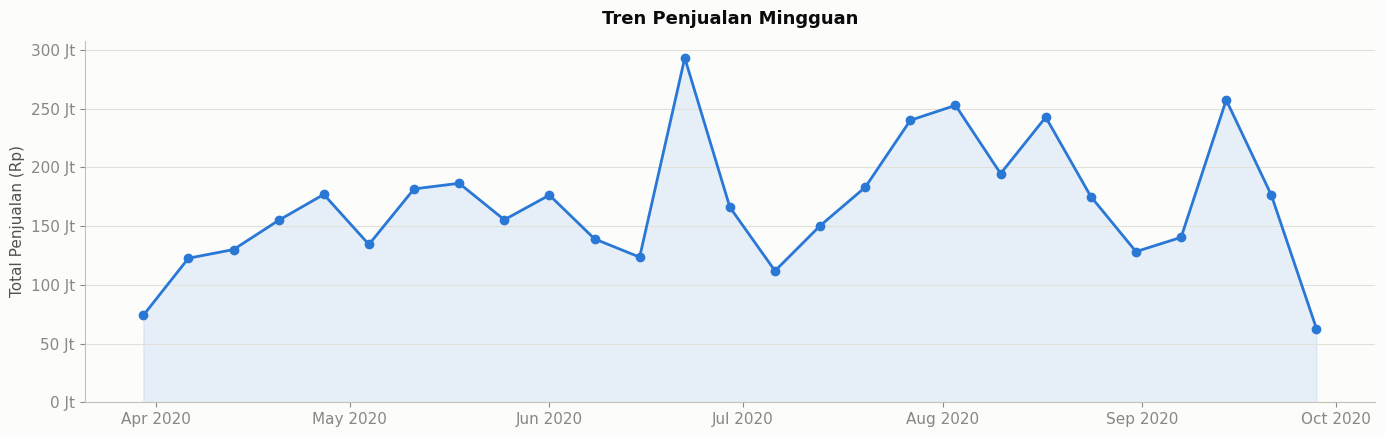

In [13]:
mingguan = df.groupby('MINGGU')['JUMLAH'].sum()

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.plot(mingguan.index, mingguan.values, color=C_RP, linewidth=2, marker='o', markersize=6)
ax.fill_between(mingguan.index, mingguan.values, color=C_RP, alpha=0.1)
ax.set_title('Tren Penjualan Mingguan')
ax.set_ylabel('Total Penjualan (Rp)')
ax.yaxis.set_major_formatter(RP_JT)
ax.set_ylim(bottom=0)
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter('%b %Y'))
plt.tight_layout()
plt.show()

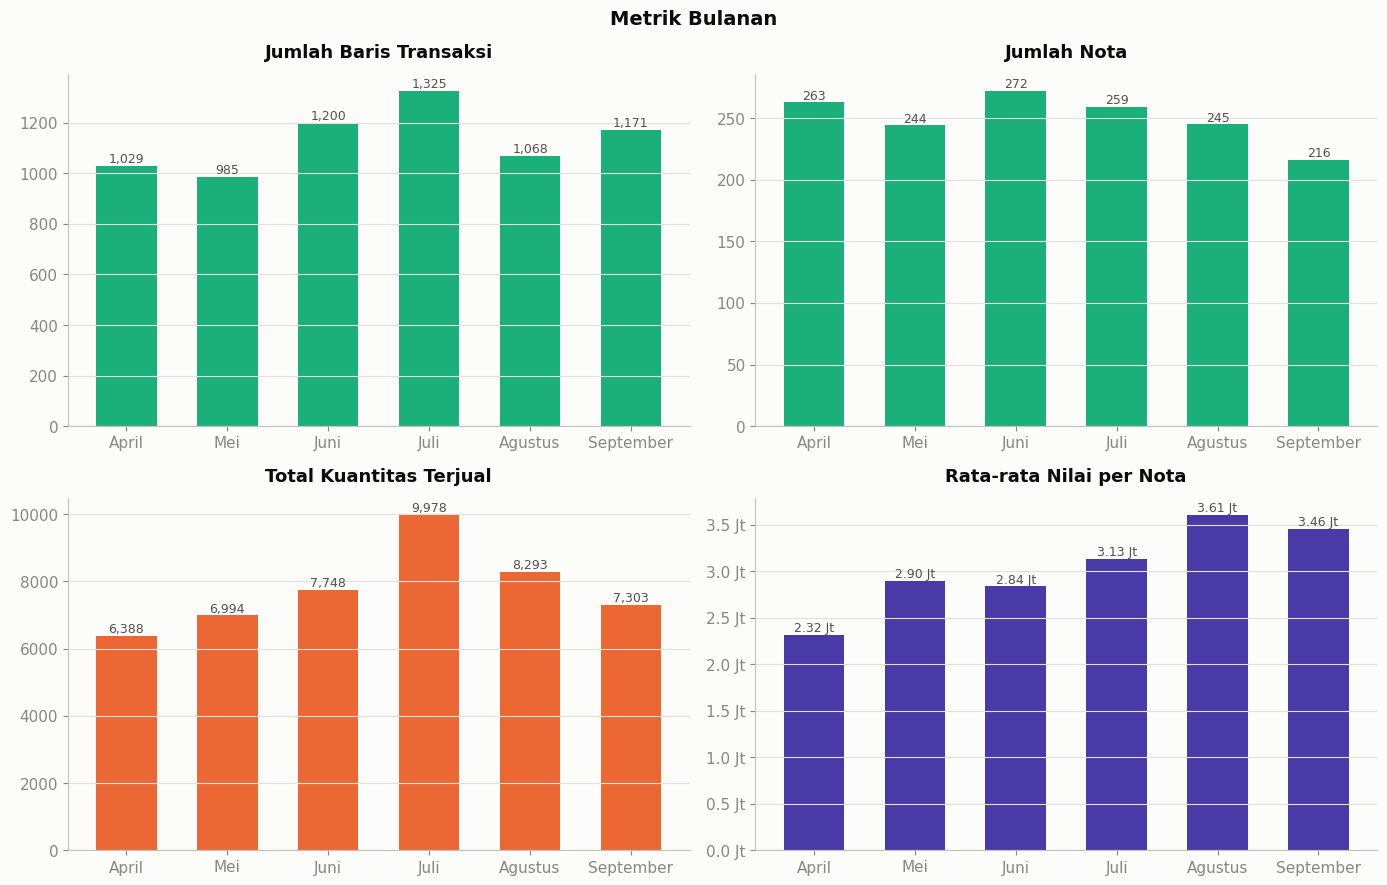

In [14]:
bulanan = df.groupby('BULAN', observed=False).agg(
    BARIS=('JUMLAH', 'size'), NOTA=('NOTA', 'nunique'), QTY=('QTY', 'sum'), PENJUALAN=('JUMLAH', 'sum'))
bulanan['RATA_NOTA'] = bulanan['PENJUALAN'] / bulanan['NOTA']

panels = [
    ('BARIS', 'Jumlah Baris Transaksi', C_CNT, lambda v: f'{v:,.0f}', None),
    ('NOTA', 'Jumlah Nota', C_CNT, lambda v: f'{v:,.0f}', None),
    ('QTY', 'Total Kuantitas Terjual', C_QTY, lambda v: f'{v:,.0f}', None),
    ('RATA_NOTA', 'Rata-rata Nilai per Nota', C_AVG, lambda v: f'{v/1e6:,.2f} Jt', RP_JT1),
]
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
for ax, (col, title, color, lab, fmt) in zip(axes.flat, panels):
    bars = ax.bar(bulanan.index.astype(str), bulanan[col].values, color=color, width=0.6)
    label_bars(ax, bars, lab)
    ax.set_title(title)
    if fmt is not None:
        ax.yaxis.set_major_formatter(fmt)
fig.suptitle('Metrik Bulanan', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

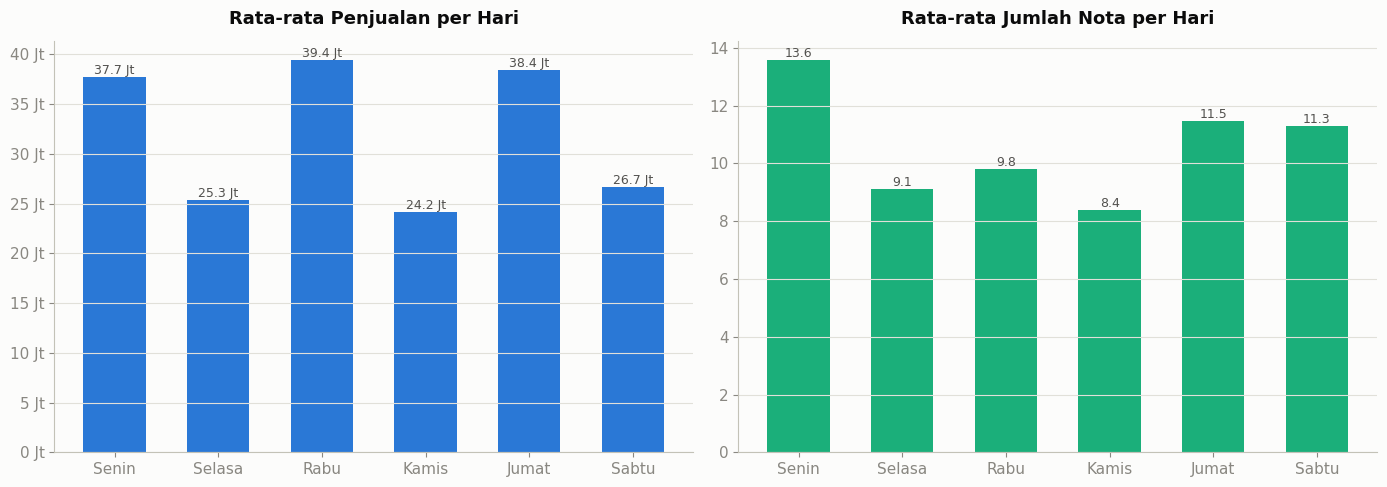

In [15]:
kerja = df[df['HARI'] != 'Minggu']
per_tgl = kerja.groupby('TGL').agg(PENJUALAN=('JUMLAH', 'sum'), NOTA=('NOTA', 'nunique'))
per_tgl['HARI'] = per_tgl.index.dayofweek.map(dict(enumerate(HARI_ORDER)))
per_hari = per_tgl.groupby('HARI')[['PENJUALAN', 'NOTA']].mean().reindex(HARI_ORDER[:-1])

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bars = axes[0].bar(per_hari.index, per_hari['PENJUALAN'], color=C_RP, width=0.6)
label_bars(axes[0], bars, lambda v: f'{v/1e6:,.1f} Jt')
axes[0].set_title('Rata-rata Penjualan per Hari')
axes[0].yaxis.set_major_formatter(RP_JT)
bars = axes[1].bar(per_hari.index, per_hari['NOTA'], color=C_CNT, width=0.6)
label_bars(axes[1], bars, lambda v: f'{v:,.1f}')
axes[1].set_title('Rata-rata Jumlah Nota per Hari')
plt.tight_layout()
plt.show()

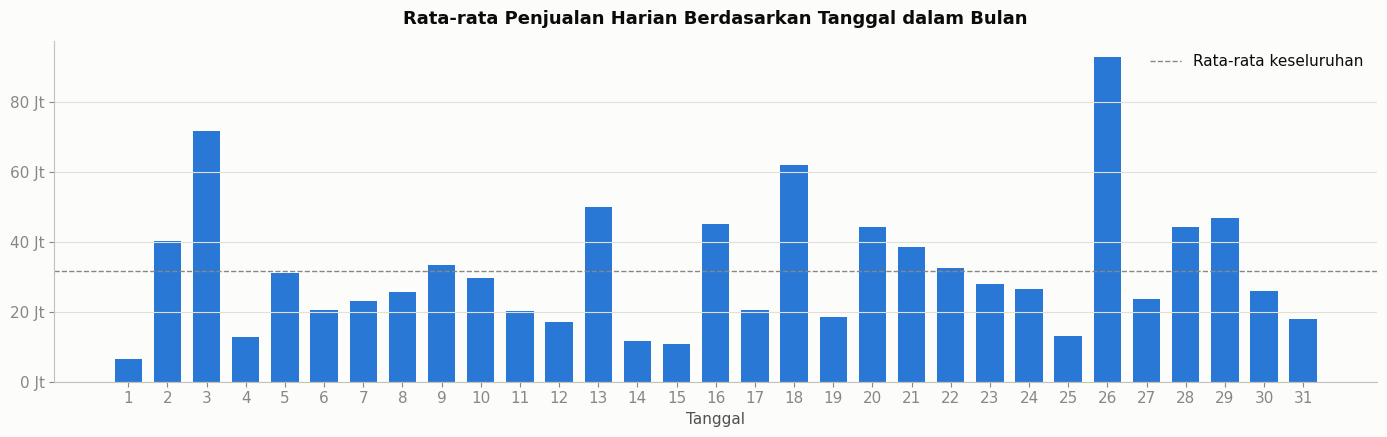

In [16]:
per_tanggal = daily.groupby(daily.index.day).mean()

fig, ax = plt.subplots(figsize=(14, 4.5))
ax.bar(per_tanggal.index, per_tanggal.values, color=C_RP, width=0.7)
ax.axhline(per_tanggal.mean(), color=INK_MUTED, linestyle='--', linewidth=1, label='Rata-rata keseluruhan')
ax.set_xticks(range(1, 32))
ax.set_xlabel('Tanggal')
ax.set_title('Rata-rata Penjualan Harian Berdasarkan Tanggal dalam Bulan')
ax.yaxis.set_major_formatter(RP_JT)
ax.legend(loc='upper right')
plt.tight_layout()
plt.show()

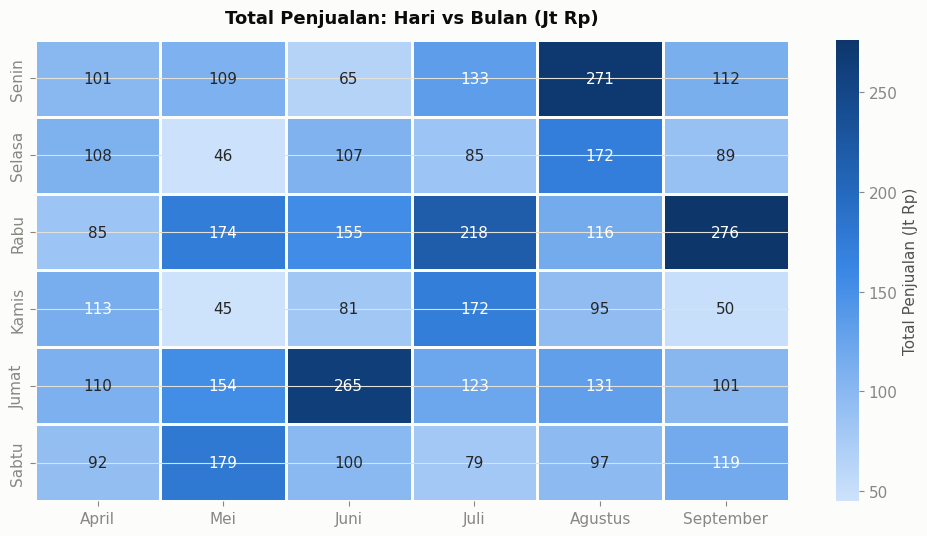

In [17]:
pivot = (kerja.pivot_table(index='HARI', columns='BULAN', values='JUMLAH', aggfunc='sum', observed=False)
              .loc[HARI_ORDER[:-1]])

fig, ax = plt.subplots(figsize=(10, 5.5))
sns.heatmap(pivot / 1e6, cmap=SEQ_BLUE, annot=True, fmt=',.0f', linewidths=2, linecolor=SURFACE,
            cbar_kws={'label': 'Total Penjualan (Jt Rp)'}, ax=ax)
ax.set_title('Total Penjualan: Hari vs Bulan (Jt Rp)')
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

## 6. Produk

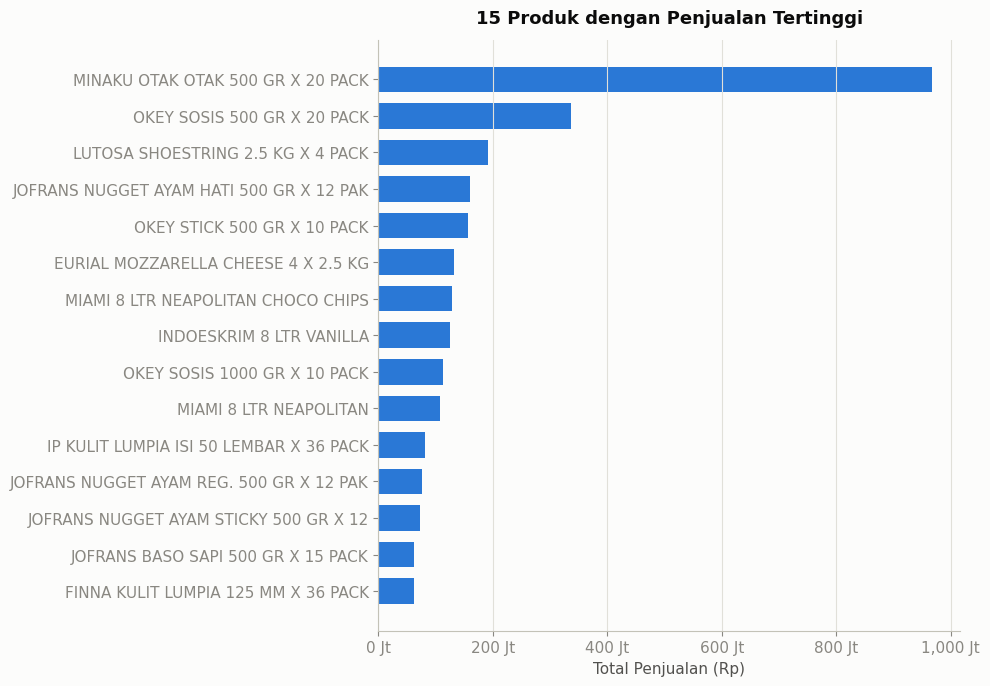

In [18]:
barh_top(df.groupby('PRODUK')['JUMLAH'].sum().nlargest(15),
         '15 Produk dengan Penjualan Tertinggi', 'Total Penjualan (Rp)', C_RP, RP_JT)

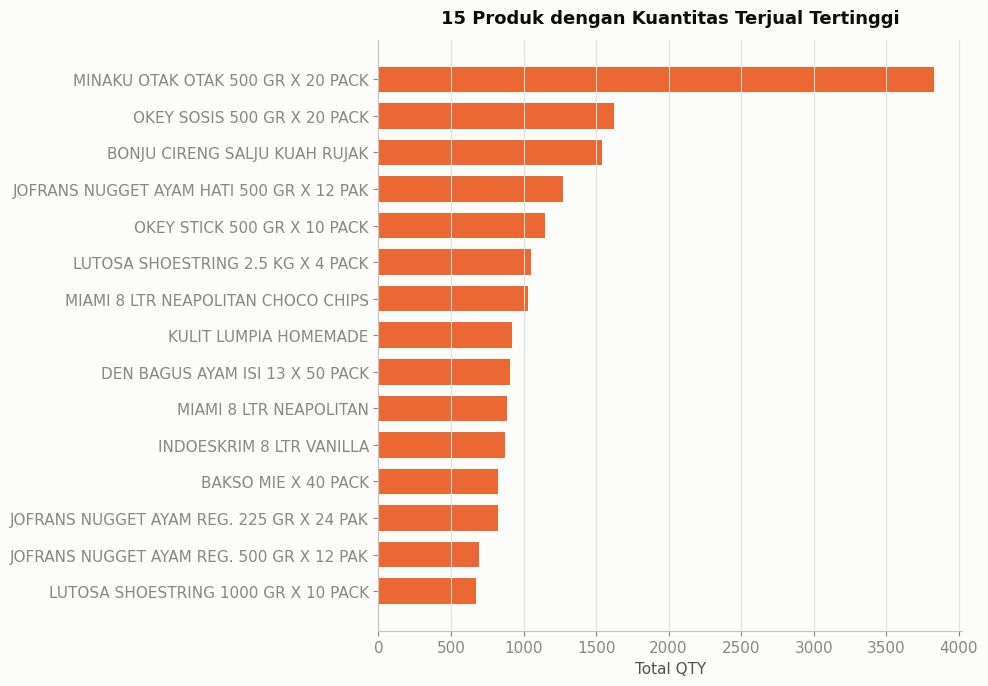

In [19]:
barh_top(df.groupby('PRODUK')['QTY'].sum().nlargest(15),
         '15 Produk dengan Kuantitas Terjual Tertinggi', 'Total QTY', C_QTY)

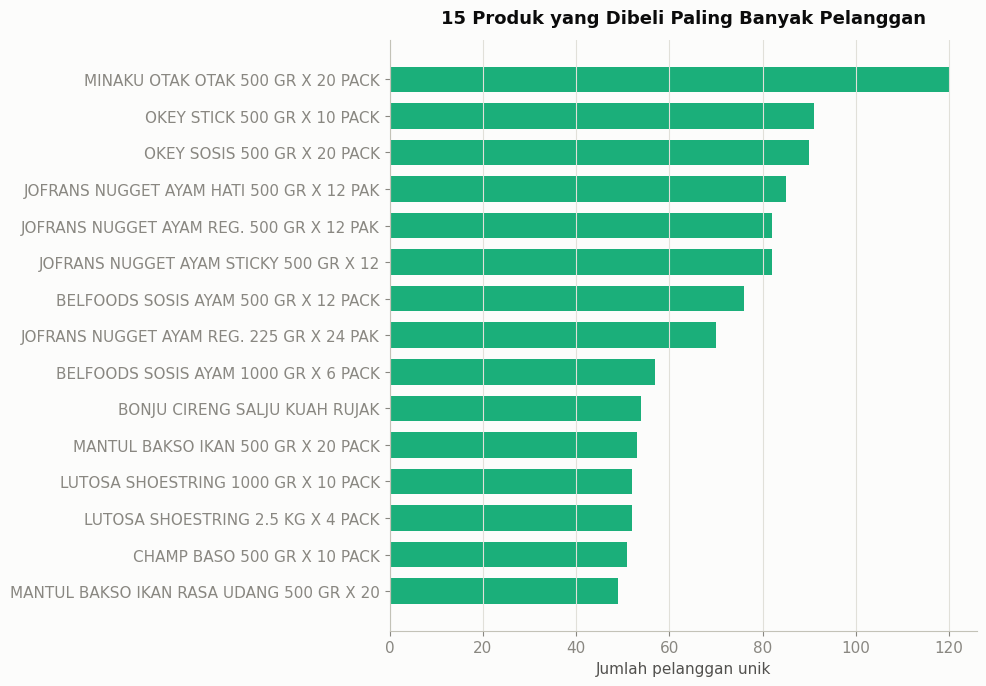

In [20]:
barh_top(df.groupby('PRODUK')['NAMA'].nunique().nlargest(15),
         '15 Produk yang Dibeli Paling Banyak Pelanggan', 'Jumlah pelanggan unik', C_CNT)

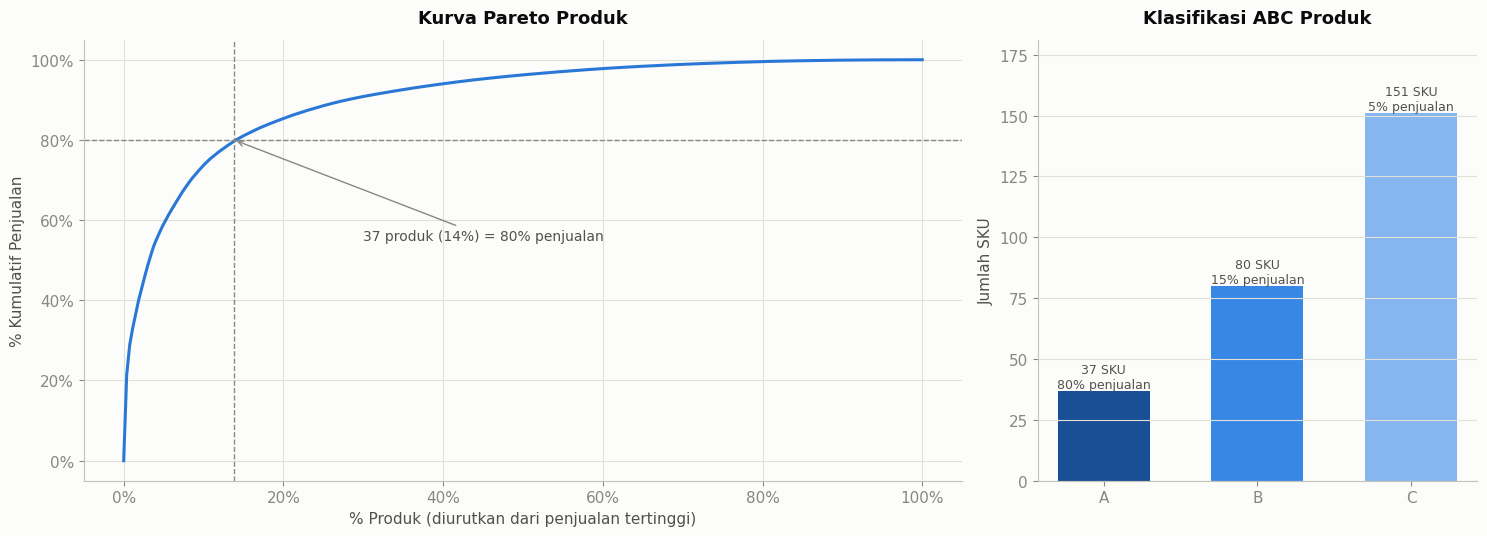

In [21]:
prod_rev = df.groupby('PRODUK')['JUMLAH'].sum().sort_values(ascending=False)
cum_share = prod_rev.cumsum() / prod_rev.sum()
prod_pct = np.arange(1, len(prod_rev) + 1) / len(prod_rev)
kelas = pd.Series(np.select([cum_share <= 0.8, cum_share <= 0.95], ['A', 'B'], default='C'), index=prod_rev.index)
n80 = (kelas == 'A').sum()

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={'width_ratios': [2, 1]})
ax = axes[0]
ax.plot(np.r_[0, prod_pct], np.r_[0, cum_share.values], color=C_RP, linewidth=2.2)
ax.axhline(0.8, color=INK_MUTED, linestyle='--', linewidth=1)
ax.axvline(n80 / len(prod_rev), color=INK_MUTED, linestyle='--', linewidth=1)
ax.annotate(f'{n80} produk ({n80/len(prod_rev):.0%}) = 80% penjualan',
            xy=(n80 / len(prod_rev), 0.8), xytext=(0.3, 0.55), fontsize=10, color=INK_SECOND,
            arrowprops=dict(arrowstyle='->', color=INK_MUTED))
ax.xaxis.set_major_formatter(PCT)
ax.yaxis.set_major_formatter(PCT)
ax.grid(axis='x', visible=True)
ax.set_xlabel('% Produk (diurutkan dari penjualan tertinggi)')
ax.set_ylabel('% Kumulatif Penjualan')
ax.set_title('Kurva Pareto Produk')

abc = pd.DataFrame({'Produk': kelas.value_counts(), 'Penjualan': prod_rev.groupby(kelas).sum()}).loc[['A', 'B', 'C']]
bars = axes[1].bar(abc.index, abc['Produk'], color=ORDINAL_BLUE, width=0.6)
for b, (k, r) in zip(bars, abc.iterrows()):
    axes[1].text(b.get_x() + b.get_width() / 2, b.get_height(),
                 f"{r['Produk']} SKU\n{r['Penjualan']/prod_rev.sum():.0%} penjualan",
                 ha='center', va='bottom', fontsize=9, color=INK_SECOND)
axes[1].set_ylim(0, abc['Produk'].max() * 1.2)
axes[1].set_title('Klasifikasi ABC Produk')
axes[1].set_ylabel('Jumlah SKU')
plt.tight_layout()
plt.show()

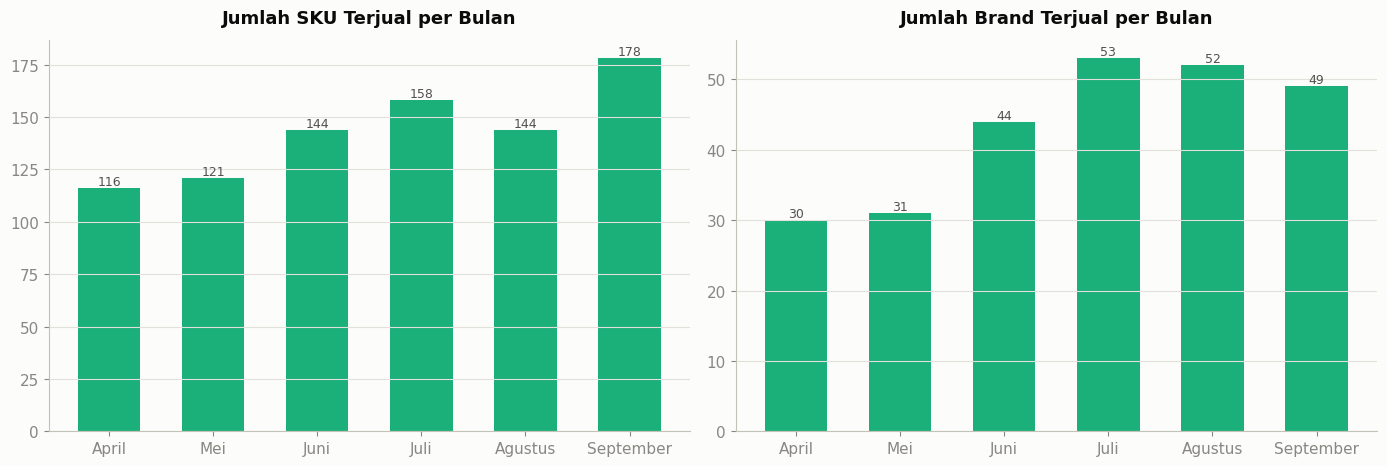

In [22]:
aktif = df.groupby('BULAN', observed=False).agg(SKU=('KODEBARA', 'nunique'), BRAND=('BRAND', 'nunique'))

fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
for ax, col, title in zip(axes, ['SKU', 'BRAND'], ['Jumlah SKU Terjual per Bulan', 'Jumlah Brand Terjual per Bulan']):
    bars = ax.bar(aktif.index.astype(str), aktif[col], color=C_CNT, width=0.6)
    label_bars(ax, bars, lambda v: f'{v:,.0f}')
    ax.set_title(title)
plt.tight_layout()
plt.show()

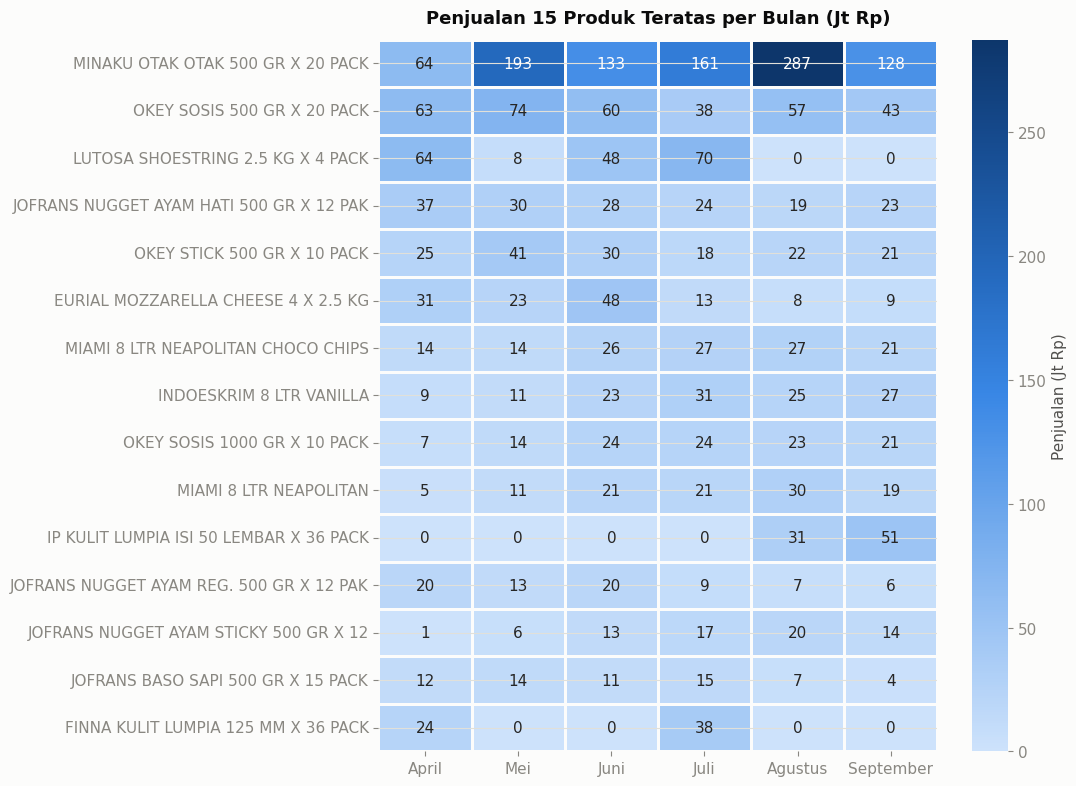

In [23]:
top15_prod = prod_rev.head(15).index
hm = (df[df['PRODUK'].isin(top15_prod)]
        .pivot_table(index='PRODUK', columns='BULAN', values='JUMLAH', aggfunc='sum', observed=False)
        .fillna(0).loc[top15_prod] / 1e6)
hm.index = [short(i, 42) for i in hm.index]

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(hm, cmap=SEQ_BLUE, annot=True, fmt=',.0f', linewidths=2, linecolor=SURFACE,
            cbar_kws={'label': 'Penjualan (Jt Rp)'}, ax=ax)
ax.set_title('Penjualan 15 Produk Teratas per Bulan (Jt Rp)')
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

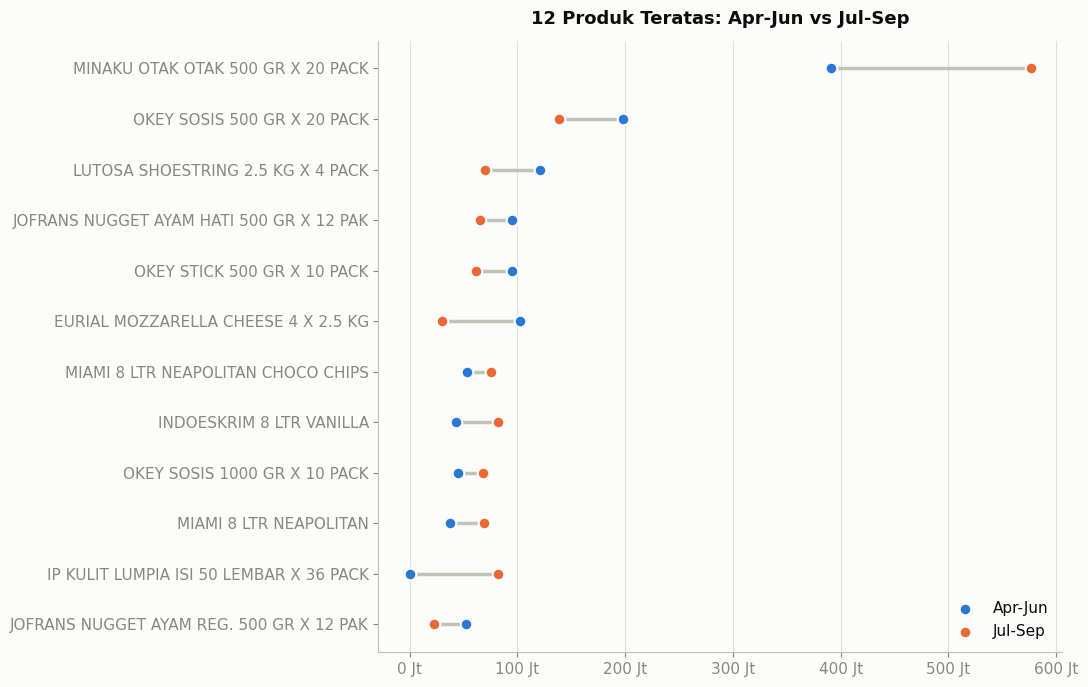

In [24]:
periode = np.where(df['BULAN_NO'] <= 2, 'Apr-Jun', 'Jul-Sep')
comp_all = df.assign(PERIODE=periode).pivot_table(index='PRODUK', columns='PERIODE', values='JUMLAH', aggfunc='sum', fill_value=0)
comp = comp_all.loc[comp_all.sum(axis=1).nlargest(12).index].iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(comp))
ax.hlines(y, comp['Apr-Jun'], comp['Jul-Sep'], color=BASELINE, linewidth=2.5)
ax.scatter(comp['Apr-Jun'], y, color=CAT[0], s=70, label='Apr-Jun', zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.scatter(comp['Jul-Sep'], y, color=CAT[1], s=70, label='Jul-Sep', zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.set_yticks(y, [short(i, 42) for i in comp.index])
ax.xaxis.set_major_formatter(RP_JT)
xgrid(ax)
ax.set_title('12 Produk Teratas: Apr-Jun vs Jul-Sep')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

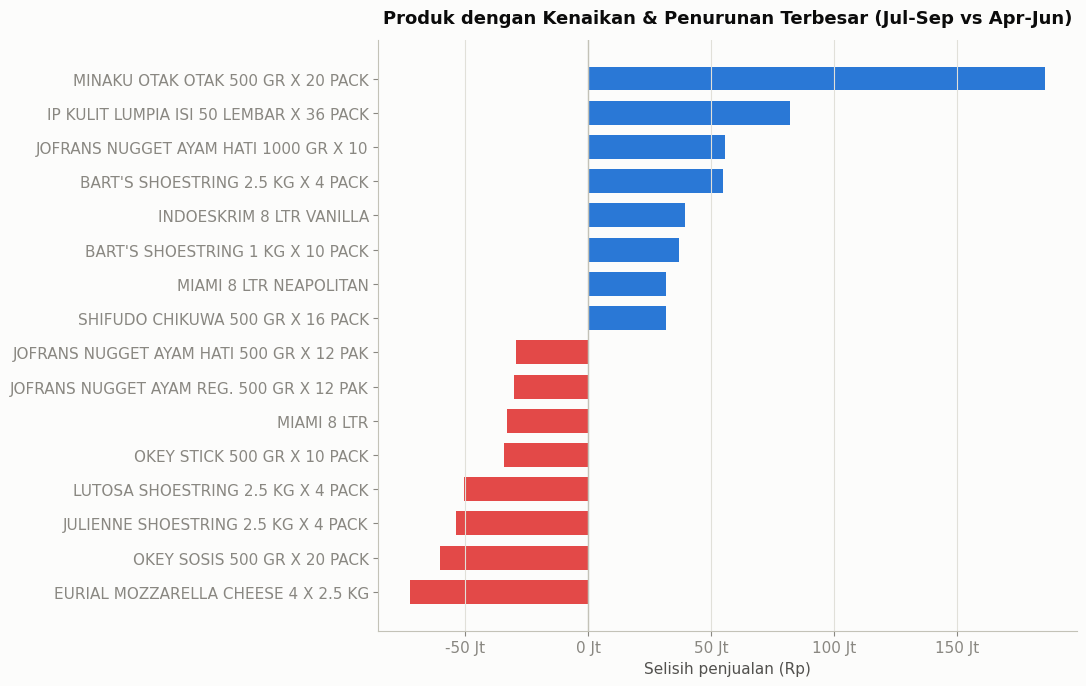

In [25]:
delta = comp_all['Jul-Sep'] - comp_all['Apr-Jun']
movers = pd.concat([delta.nlargest(8), delta.nsmallest(8)]).sort_values()

fig, ax = plt.subplots(figsize=(11, 7))
y = np.arange(len(movers))
ax.barh(y, movers.values, color=[POS if v >= 0 else NEG for v in movers.values], height=0.7)
ax.set_yticks(y, [short(i, 42) for i in movers.index])
ax.axvline(0, color=BASELINE, linewidth=1)
ax.xaxis.set_major_formatter(RP_JT)
xgrid(ax)
ax.set_title('Produk dengan Kenaikan & Penurunan Terbesar (Jul-Sep vs Apr-Jun)')
ax.set_xlabel('Selisih penjualan (Rp)')
plt.tight_layout()
plt.show()

## 7. Kategori Produk

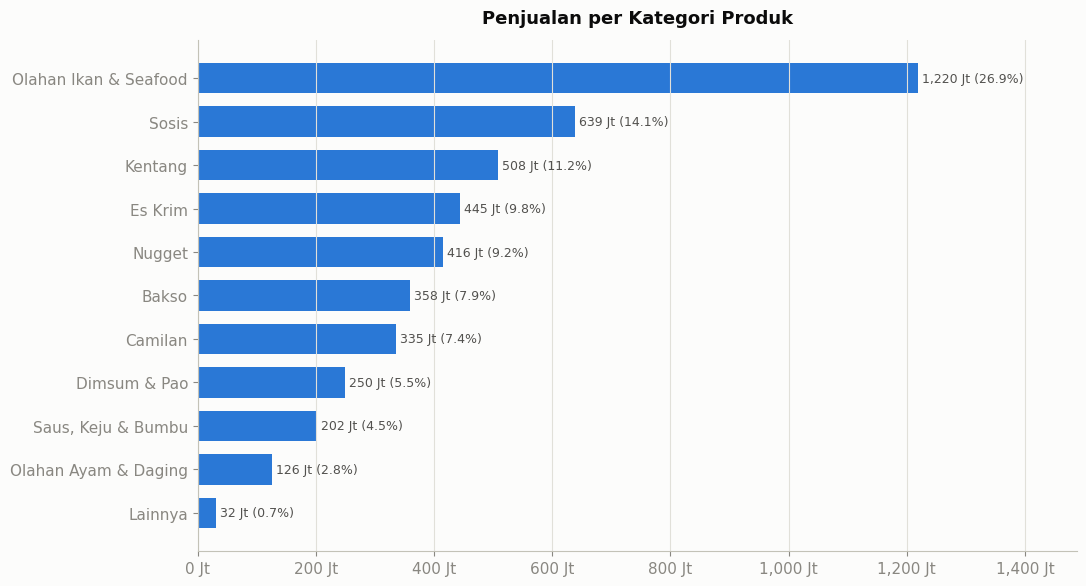

In [26]:
kat_rev = df.groupby('KATEGORI')['JUMLAH'].sum().sort_values(ascending=False)
total_rev = kat_rev.sum()

fig, ax = plt.subplots(figsize=(11, 6))
y = np.arange(len(kat_rev))
bars = ax.barh(y, kat_rev.values[::-1], color=C_RP, height=0.7)
ax.set_yticks(y, kat_rev.index[::-1])
label_bars(ax, bars, lambda v: f'{v/1e6:,.0f} Jt ({v/total_rev:.1%})', horizontal=True)
ax.xaxis.set_major_formatter(RP_JT)
ax.set_xlim(0, kat_rev.max() * 1.22)
xgrid(ax)
ax.set_title('Penjualan per Kategori Produk')
plt.tight_layout()
plt.show()

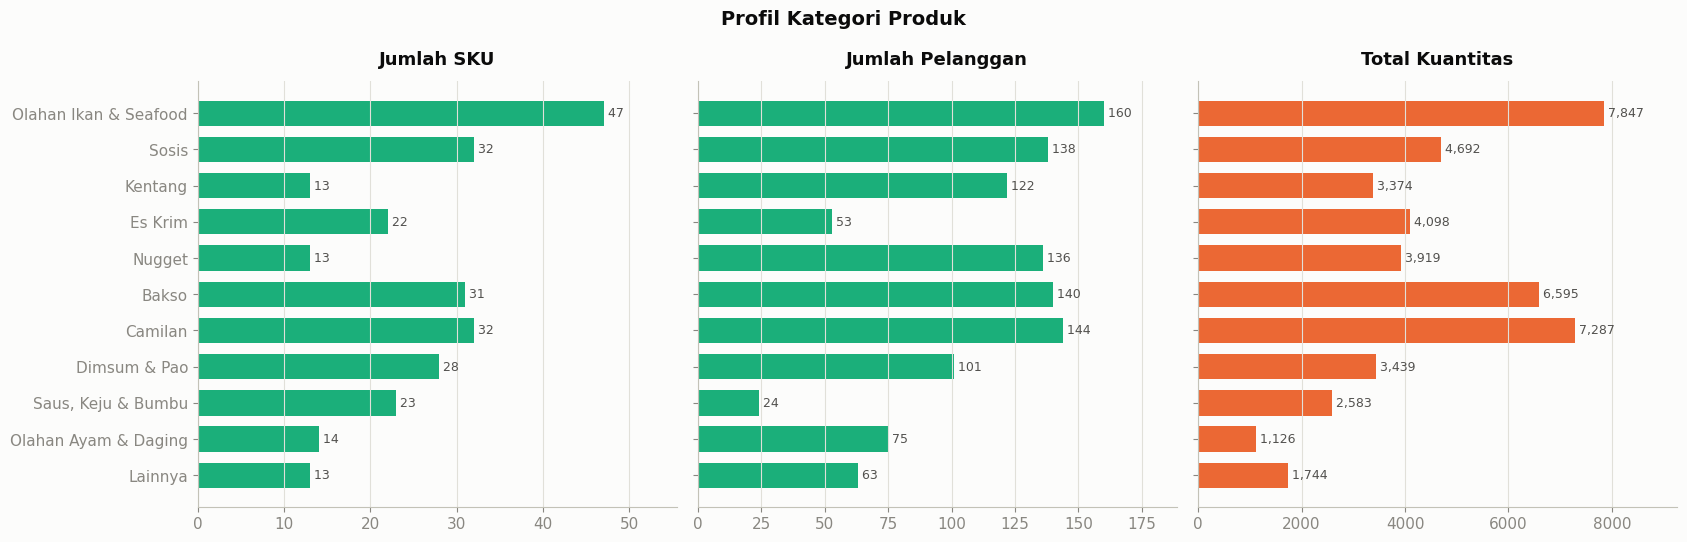

In [27]:
kat_stat = df.groupby('KATEGORI').agg(SKU=('KODEBARA', 'nunique'), PELANGGAN=('NAMA', 'nunique'),
                                      QTY=('QTY', 'sum')).loc[kat_rev.index]

fig, axes = plt.subplots(1, 3, figsize=(17, 5.5), sharey=True)
for ax, (col, title, color) in zip(axes, [('SKU', 'Jumlah SKU', C_CNT), ('PELANGGAN', 'Jumlah Pelanggan', C_CNT), ('QTY', 'Total Kuantitas', C_QTY)]):
    y = np.arange(len(kat_stat))
    bars = ax.barh(y, kat_stat[col].values[::-1], color=color, height=0.7)
    label_bars(ax, bars, lambda v: f'{v:,.0f}', horizontal=True)
    ax.set_yticks(y, kat_stat.index[::-1])
    ax.set_xlim(0, kat_stat[col].max() * 1.18)
    ax.set_title(title)
    xgrid(ax)
fig.suptitle('Profil Kategori Produk', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

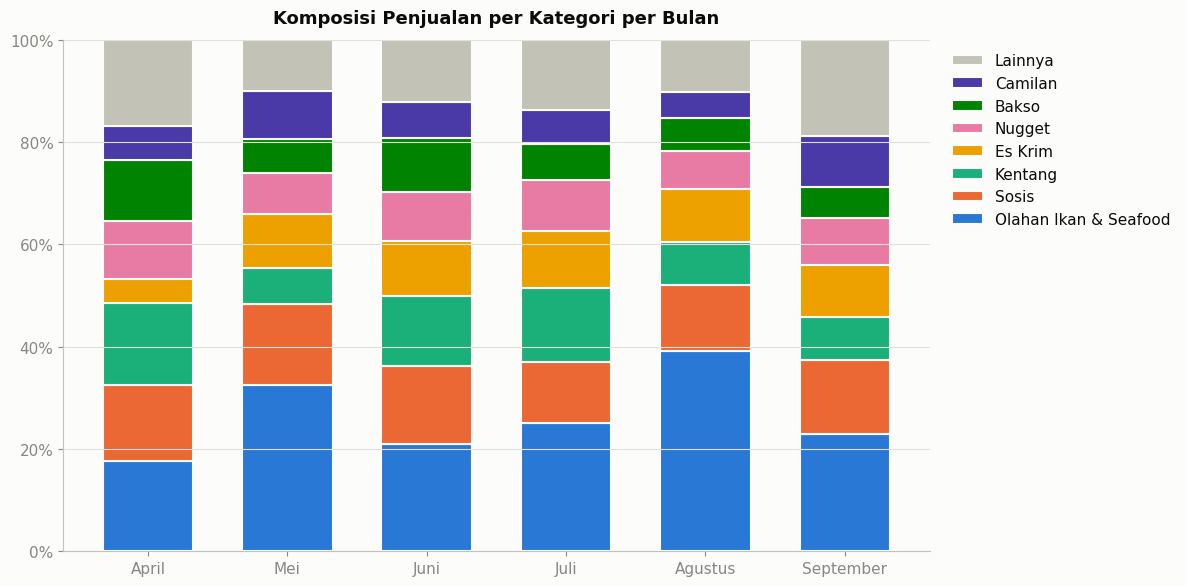

In [28]:
share_stacked('KATEGORI', 'Komposisi Penjualan per Kategori per Bulan')

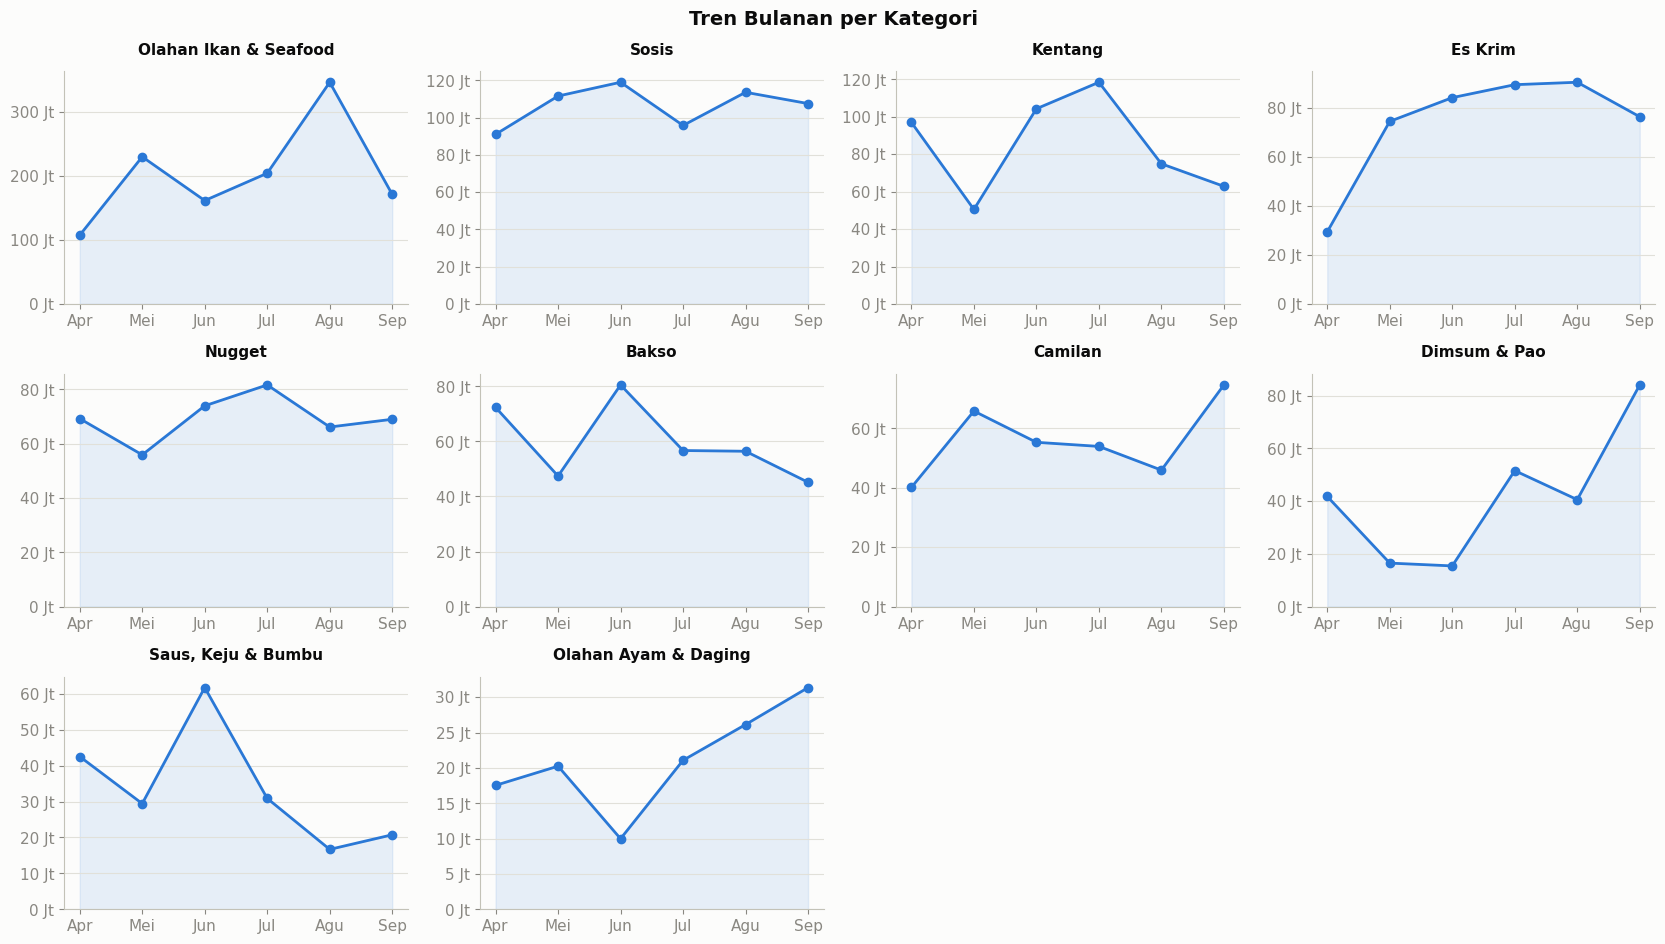

In [29]:
small_multiples('KATEGORI', [k for k in kat_rev.index if k != 'Lainnya'], 'Tren Bulanan per Kategori')

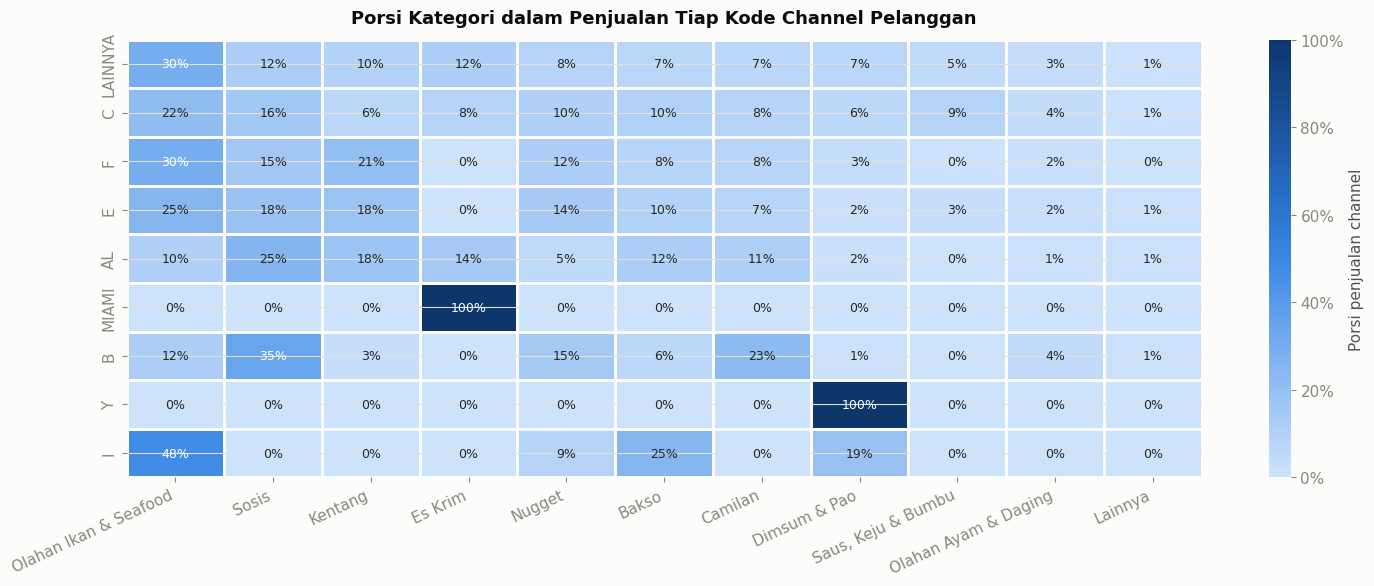

In [30]:
ck = df.pivot_table(index='CHANNEL', columns='KATEGORI', values='JUMLAH', aggfunc='sum', fill_value=0)
ck = ck.loc[ck.sum(axis=1).sort_values(ascending=False).index, kat_rev.index]
ck_share = ck.div(ck.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(ck_share, cmap=SEQ_BLUE, annot=True, fmt='.0%', vmin=0, linewidths=2, linecolor=SURFACE,
            annot_kws={'fontsize': 9}, cbar_kws={'label': 'Porsi penjualan channel', 'format': PCT}, ax=ax)
ax.set_title('Porsi Kategori dalam Penjualan Tiap Kode Channel Pelanggan')
ax.set_xlabel('')
ax.set_ylabel('')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.show()

## 8. Brand

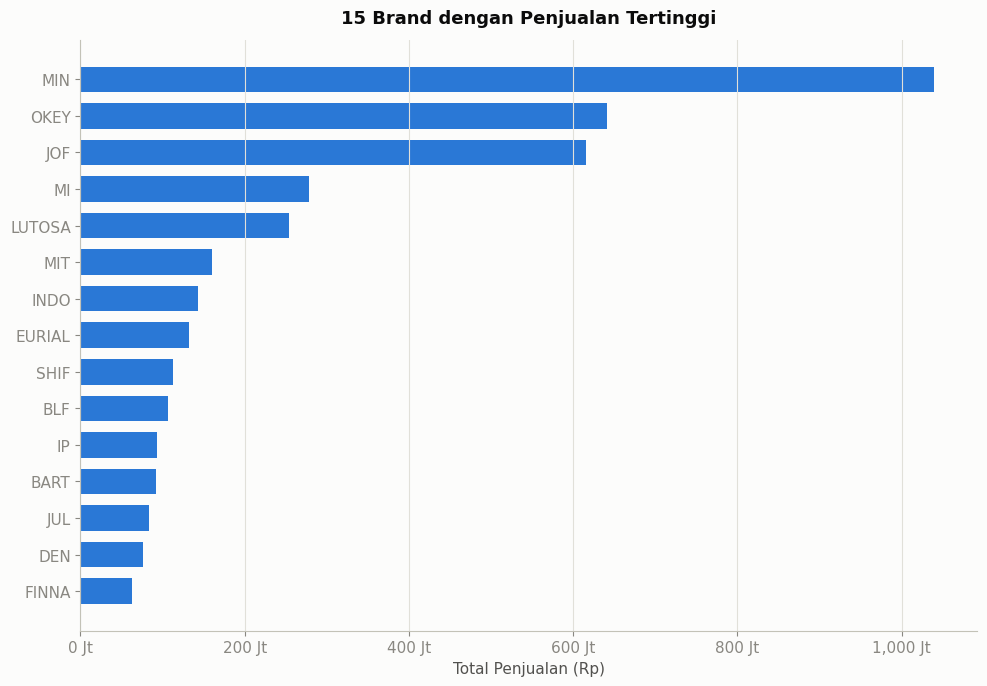

In [31]:
brand_rev = df.groupby('BRAND')['JUMLAH'].sum().sort_values(ascending=False)
barh_top(brand_rev.head(15), '15 Brand dengan Penjualan Tertinggi', 'Total Penjualan (Rp)', C_RP, RP_JT)

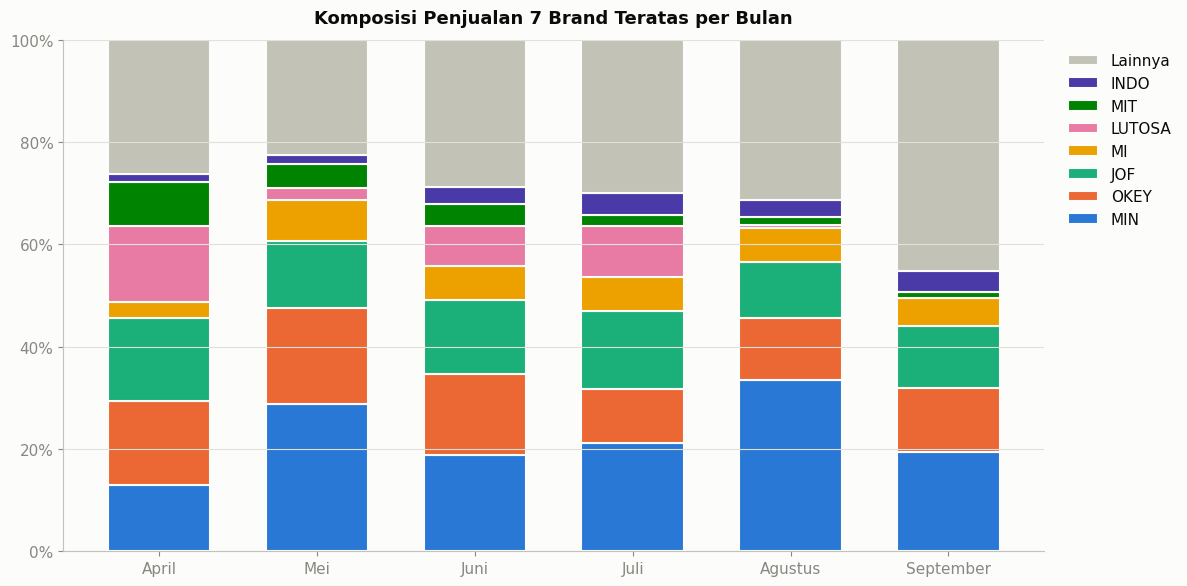

In [32]:
share_stacked('BRAND', 'Komposisi Penjualan 7 Brand Teratas per Bulan')

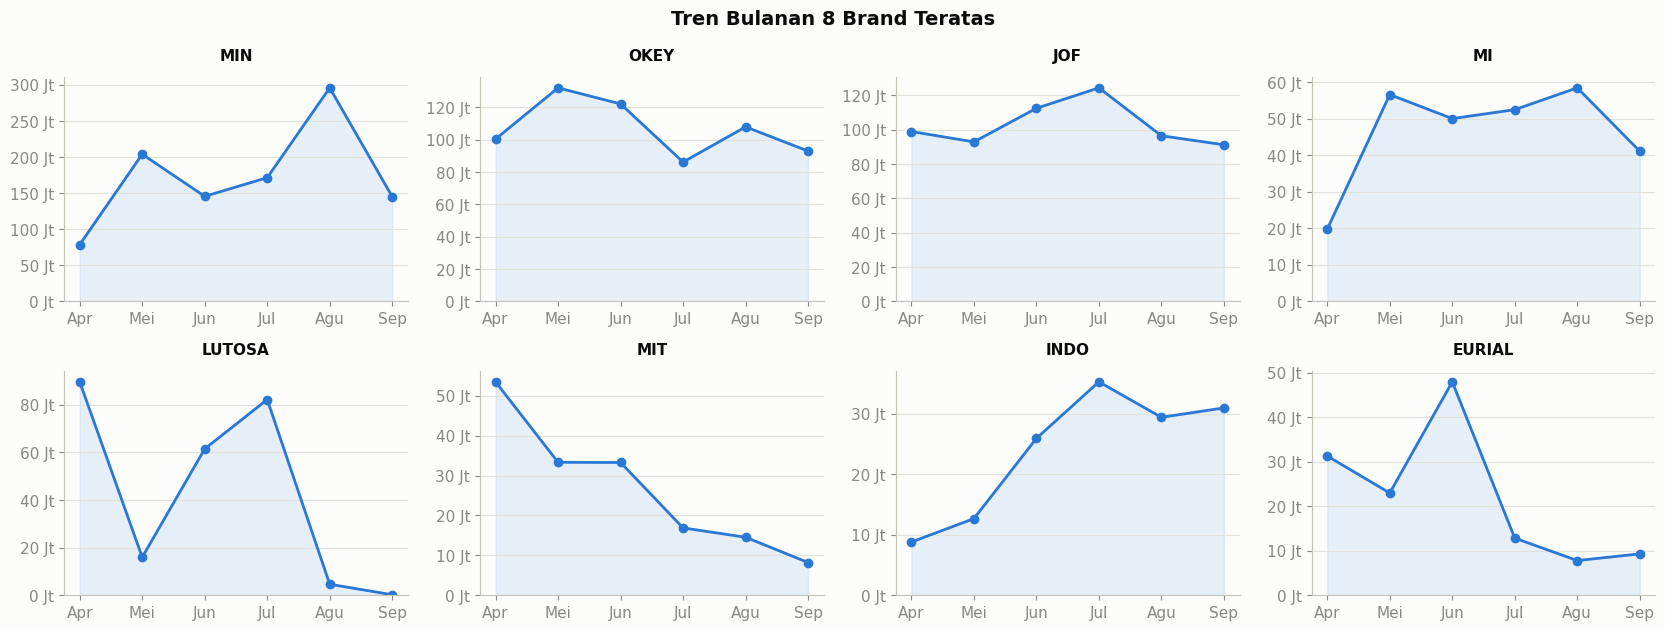

In [33]:
small_multiples('BRAND', brand_rev.head(8).index.tolist(), 'Tren Bulanan 8 Brand Teratas')

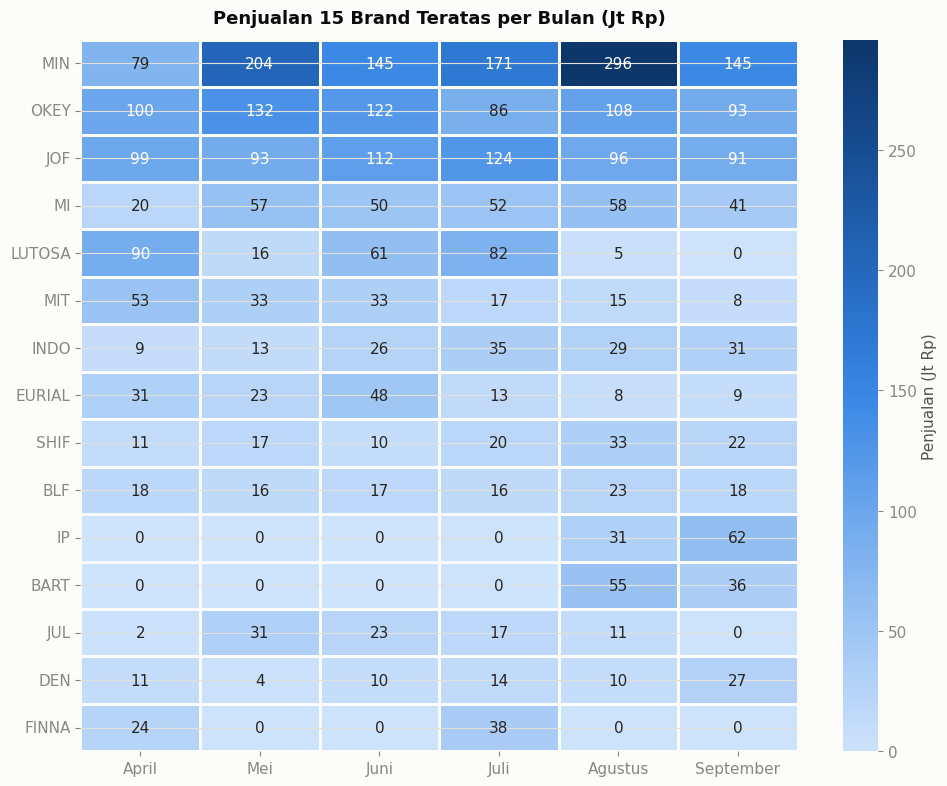

In [34]:
top15_brand = brand_rev.head(15).index
hb = (df[df['BRAND'].isin(top15_brand)]
        .pivot_table(index='BRAND', columns='BULAN', values='JUMLAH', aggfunc='sum', observed=False)
        .fillna(0).loc[top15_brand] / 1e6)

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(hb, cmap=SEQ_BLUE, annot=True, fmt=',.0f', linewidths=2, linecolor=SURFACE,
            cbar_kws={'label': 'Penjualan (Jt Rp)'}, ax=ax)
ax.set_title('Penjualan 15 Brand Teratas per Bulan (Jt Rp)')
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

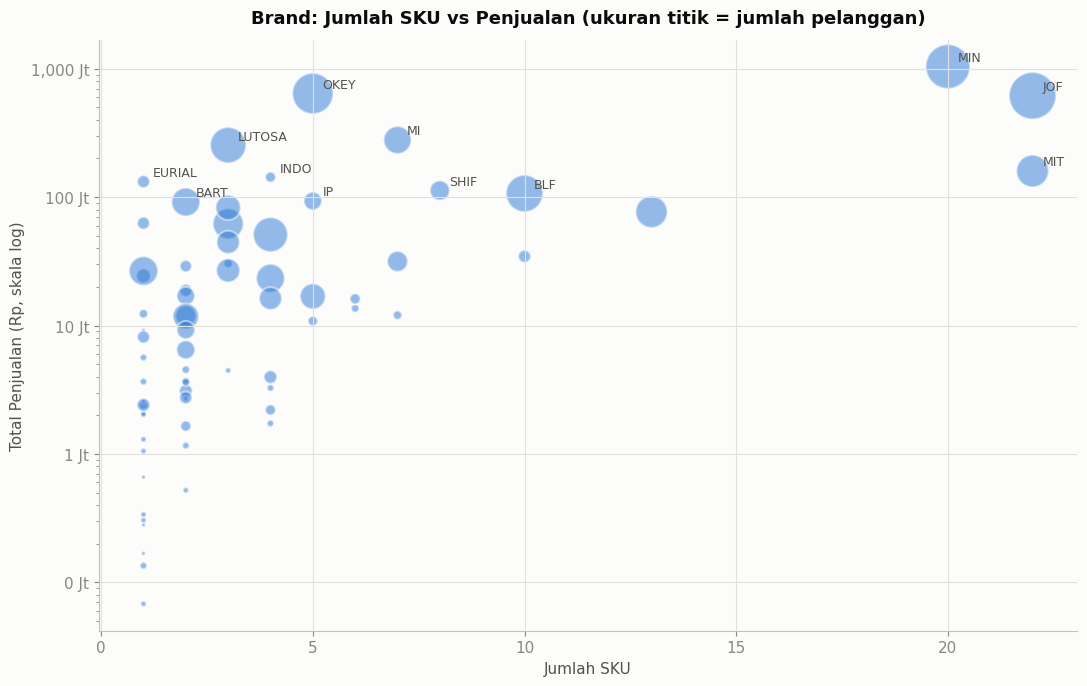

In [35]:
bstat = df.groupby('BRAND').agg(SKU=('KODEBARA', 'nunique'), PENJUALAN=('JUMLAH', 'sum'), PELANGGAN=('NAMA', 'nunique'))
bstat = bstat[bstat['PENJUALAN'] > 0]

fig, ax = plt.subplots(figsize=(11, 7))
ax.scatter(bstat['SKU'], bstat['PENJUALAN'], s=bstat['PELANGGAN'] * 8, color=C_RP, alpha=0.5,
           edgecolor=SURFACE, linewidth=1.5)
for b, r in bstat.nlargest(12, 'PENJUALAN').iterrows():
    ax.annotate(b, (r['SKU'], r['PENJUALAN']), xytext=(7, 4), textcoords='offset points', fontsize=9, color=INK_SECOND)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(RP_JT)
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.grid(axis='x', visible=True)
ax.set_xlabel('Jumlah SKU')
ax.set_ylabel('Total Penjualan (Rp, skala log)')
ax.set_title('Brand: Jumlah SKU vs Penjualan (ukuran titik = jumlah pelanggan)')
plt.tight_layout()
plt.show()

## 9. Pelanggan

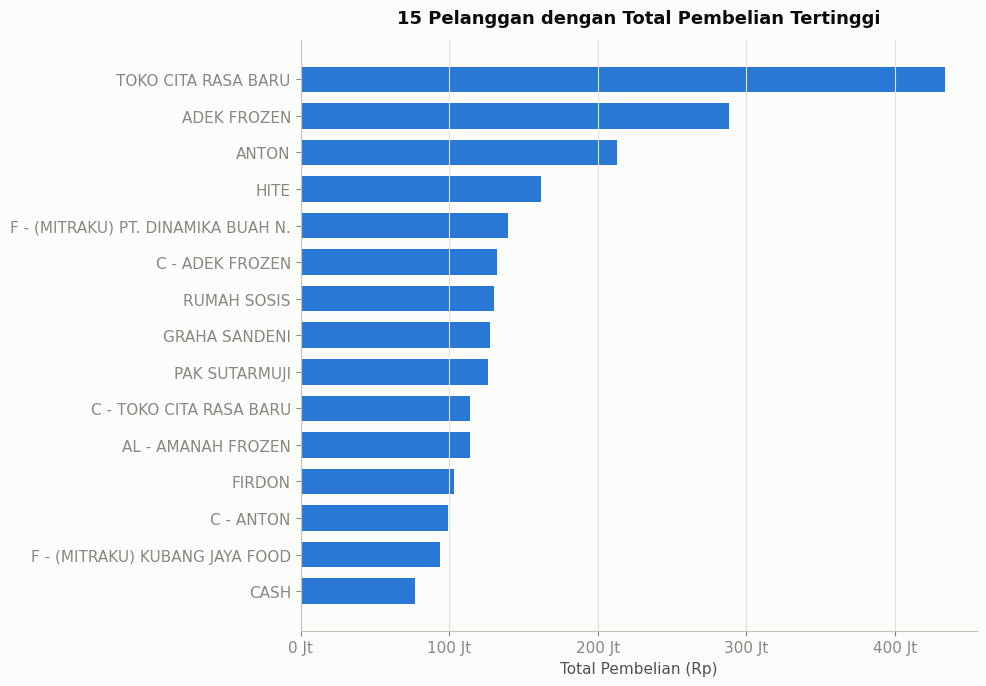

In [36]:
cust_rev = df.groupby('NAMA')['JUMLAH'].sum().sort_values(ascending=False)
barh_top(cust_rev.head(15), '15 Pelanggan dengan Total Pembelian Tertinggi', 'Total Pembelian (Rp)', C_RP, RP_JT)

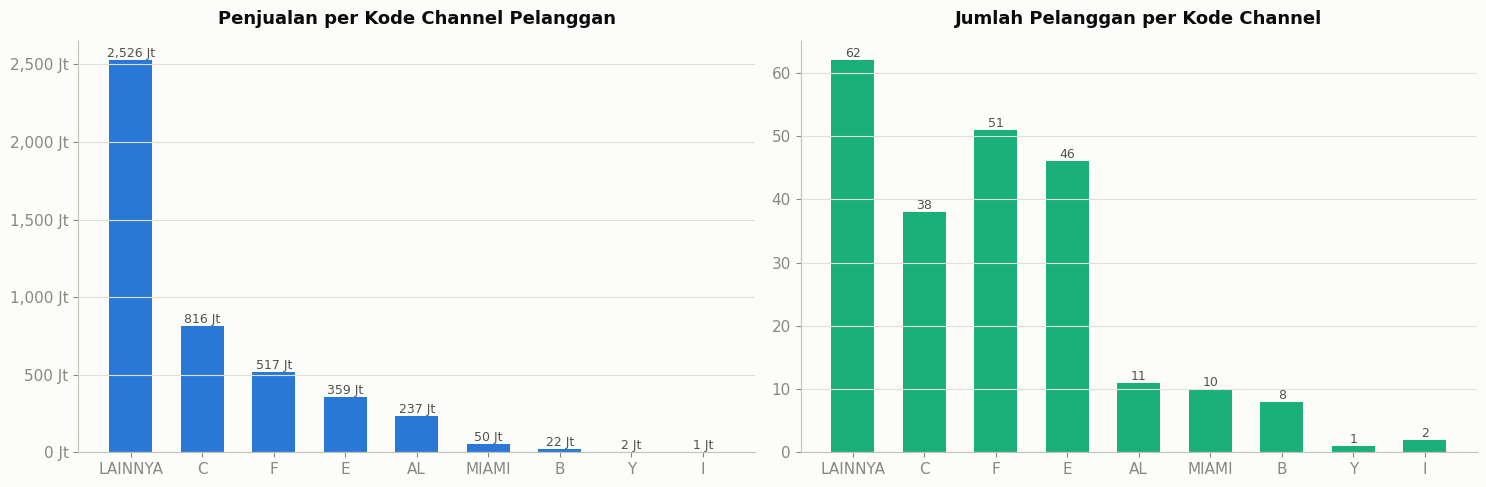

In [37]:
ch = df.groupby('CHANNEL').agg(PENJUALAN=('JUMLAH', 'sum'), PELANGGAN=('NAMA', 'nunique')).sort_values('PENJUALAN', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
bars = axes[0].bar(ch.index, ch['PENJUALAN'], color=C_RP, width=0.6)
label_bars(axes[0], bars, lambda v: f'{v/1e6:,.0f} Jt')
axes[0].yaxis.set_major_formatter(RP_JT)
axes[0].set_title('Penjualan per Kode Channel Pelanggan')
bars = axes[1].bar(ch.index, ch['PELANGGAN'], color=C_CNT, width=0.6)
label_bars(axes[1], bars, lambda v: f'{v:,.0f}')
axes[1].set_title('Jumlah Pelanggan per Kode Channel')
plt.tight_layout()
plt.show()

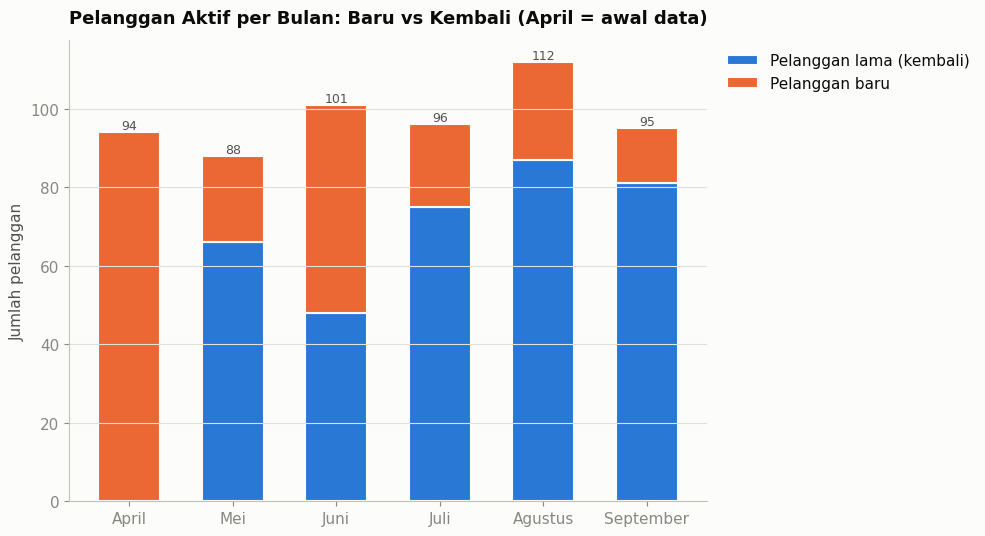

In [38]:
first_month = df.groupby('NAMA')['BULAN_NO'].min()
cm = df[['NAMA', 'BULAN_NO']].drop_duplicates()
cm['STATUS'] = np.where(cm['BULAN_NO'] == cm['NAMA'].map(first_month), 'Baru', 'Kembali')
nr = cm.pivot_table(index='BULAN_NO', columns='STATUS', values='NAMA', aggfunc='count').fillna(0)
nr = nr.reindex(columns=['Kembali', 'Baru'], fill_value=0)
labels = [MONTH_ORDER[i] for i in nr.index]

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.bar(labels, nr['Kembali'], color=CAT[0], width=0.6, label='Pelanggan lama (kembali)', edgecolor=SURFACE, linewidth=1.5)
ax.bar(labels, nr['Baru'], bottom=nr['Kembali'], color=CAT[1], width=0.6, label='Pelanggan baru', edgecolor=SURFACE, linewidth=1.5)
for i, (k, b) in enumerate(zip(nr['Kembali'], nr['Baru'])):
    ax.text(i, k + b, f'{int(k + b)}', ha='center', va='bottom', fontsize=9, color=INK_SECOND)
ax.set_title('Pelanggan Aktif per Bulan: Baru vs Kembali (April = awal data)')
ax.set_ylabel('Jumlah pelanggan')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

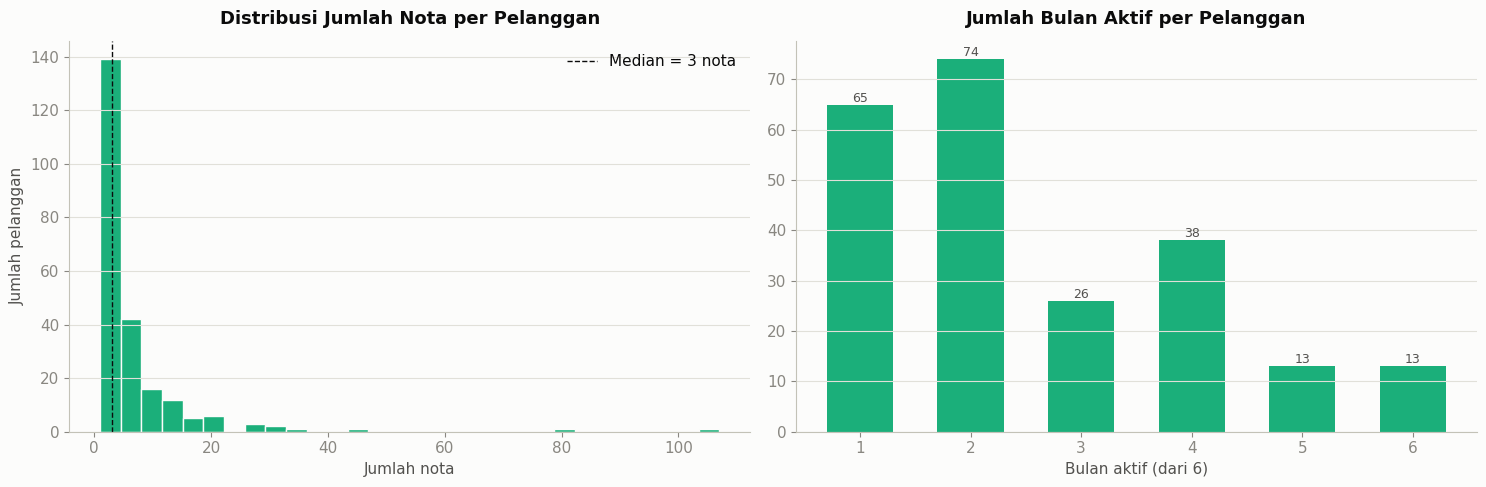

In [39]:
nota_per_cust = df.groupby('NAMA')['NOTA'].nunique()
bulan_aktif = df.groupby('NAMA')['BULAN_NO'].nunique().value_counts().sort_index()

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].hist(nota_per_cust, bins=30, color=C_CNT, edgecolor=SURFACE)
axes[0].axvline(nota_per_cust.median(), color=INK, linestyle='--', linewidth=1,
                label=f'Median = {nota_per_cust.median():.0f} nota')
axes[0].set_title('Distribusi Jumlah Nota per Pelanggan')
axes[0].set_xlabel('Jumlah nota')
axes[0].set_ylabel('Jumlah pelanggan')
axes[0].legend()
bars = axes[1].bar(bulan_aktif.index.astype(str), bulan_aktif.values, color=C_CNT, width=0.6)
label_bars(axes[1], bars, lambda v: f'{v:,.0f}')
axes[1].set_title('Jumlah Bulan Aktif per Pelanggan')
axes[1].set_xlabel('Bulan aktif (dari 6)')
plt.tight_layout()
plt.show()

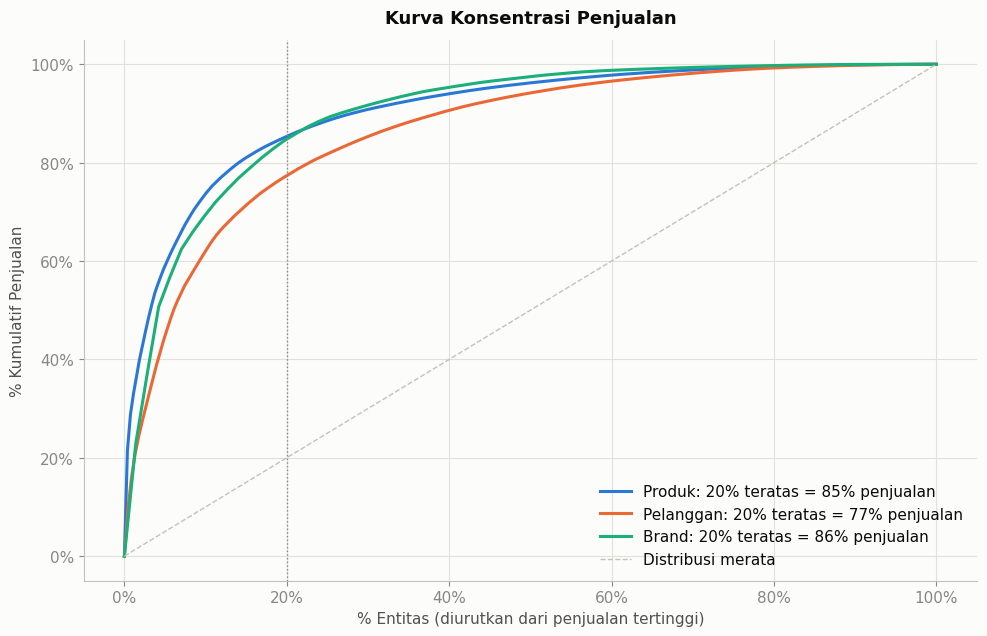

In [40]:
fig, ax = plt.subplots(figsize=(10, 6.5))
for (label, col), color in zip([('Produk', 'KODEBARA'), ('Pelanggan', 'NAMA'), ('Brand', 'BRAND')], CAT[:3]):
    s = df.groupby(col)['JUMLAH'].sum().sort_values(ascending=False)
    x = np.arange(1, len(s) + 1) / len(s)
    y = (s.cumsum() / s.sum()).values
    top20 = y[int(np.ceil(0.2 * len(s))) - 1]
    ax.plot(np.r_[0, x], np.r_[0, y], color=color, linewidth=2.2, label=f'{label}: 20% teratas = {top20:.0%} penjualan')
ax.plot([0, 1], [0, 1], color=BASELINE, linestyle='--', linewidth=1, label='Distribusi merata')
ax.axvline(0.2, color=INK_MUTED, linestyle=':', linewidth=1)
ax.xaxis.set_major_formatter(PCT)
ax.yaxis.set_major_formatter(PCT)
ax.grid(axis='x', visible=True)
ax.set_xlabel('% Entitas (diurutkan dari penjualan tertinggi)')
ax.set_ylabel('% Kumulatif Penjualan')
ax.set_title('Kurva Konsentrasi Penjualan')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

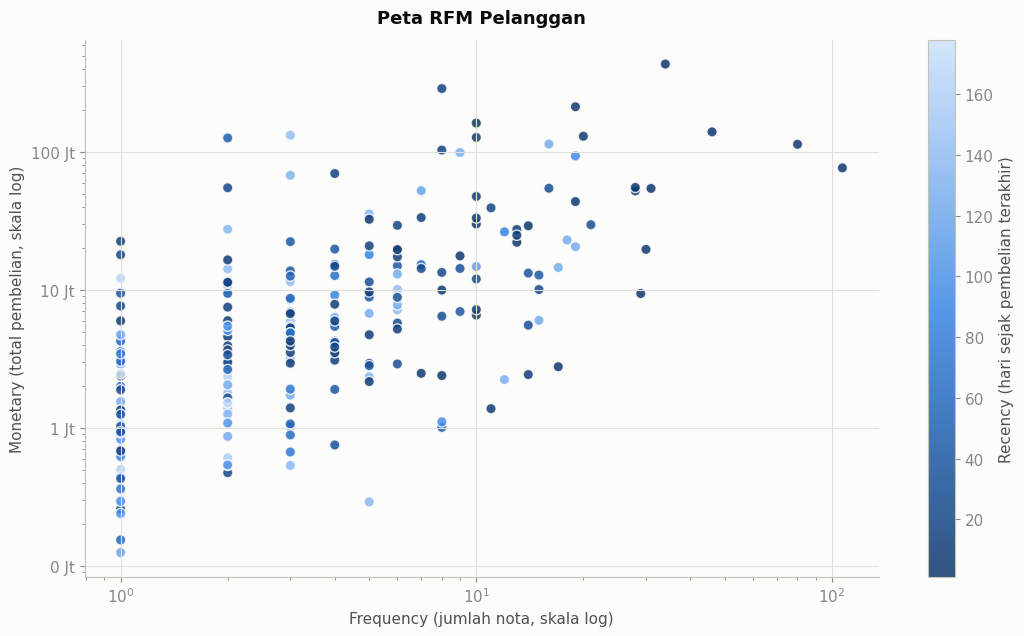

In [41]:
ref_date = df['TGL'].max() + pd.Timedelta(days=1)
rfm = df.groupby('NAMA').agg(
    RECENCY=('TGL', lambda s: (ref_date - s.max()).days),
    FREQUENCY=('NOTA', 'nunique'),
    MONETARY=('JUMLAH', 'sum'),
)
rfm['R'] = pd.qcut(rfm['RECENCY'].rank(method='first'), 4, labels=[4, 3, 2, 1]).astype(int)
rfm['F'] = pd.qcut(rfm['FREQUENCY'].rank(method='first'), 4, labels=[1, 2, 3, 4]).astype(int)
rfm['SEGMEN'] = np.select(
    [(rfm['R'] >= 3) & (rfm['F'] >= 3), (rfm['R'] <= 2) & (rfm['F'] >= 3), rfm['R'] >= 3],
    ['Champion', 'Berisiko Hilang', 'Potensial'], default='Tidak Aktif')

fig, ax = plt.subplots(figsize=(11, 6.5))
pos = rfm[rfm['MONETARY'] > 0]
sc = ax.scatter(pos['FREQUENCY'], pos['MONETARY'], c=pos['RECENCY'], cmap=SEQ_BLUE.reversed(),
                s=55, alpha=0.85, edgecolor=SURFACE, linewidth=1)
cb = plt.colorbar(sc, ax=ax)
cb.set_label('Recency (hari sejak pembelian terakhir)')
ax.set_xscale('log')
ax.set_yscale('log')
ax.yaxis.set_major_formatter(RP_JT)
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.grid(axis='x', visible=True)
ax.set_xlabel('Frequency (jumlah nota, skala log)')
ax.set_ylabel('Monetary (total pembelian, skala log)')
ax.set_title('Peta RFM Pelanggan')
plt.tight_layout()
plt.show()

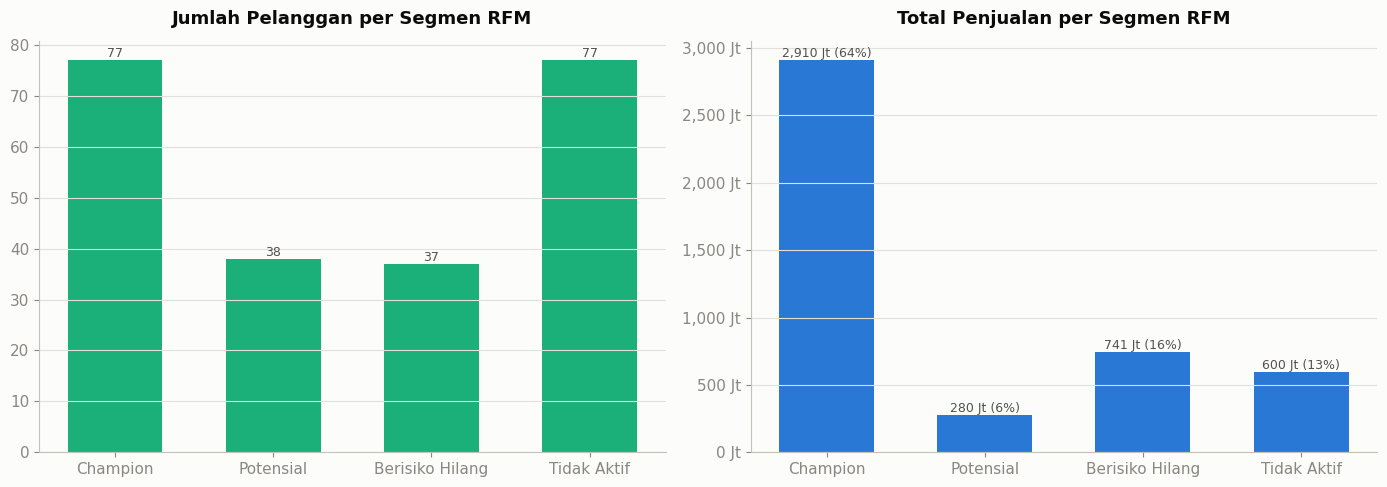

In [42]:
seg_order = ['Champion', 'Potensial', 'Berisiko Hilang', 'Tidak Aktif']
seg = rfm.groupby('SEGMEN').agg(PELANGGAN=('MONETARY', 'size'), PENJUALAN=('MONETARY', 'sum')).reindex(seg_order)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
bars = axes[0].bar(seg.index, seg['PELANGGAN'], color=C_CNT, width=0.6)
label_bars(axes[0], bars, lambda v: f'{v:,.0f}')
axes[0].set_title('Jumlah Pelanggan per Segmen RFM')
bars = axes[1].bar(seg.index, seg['PENJUALAN'], color=C_RP, width=0.6)
label_bars(axes[1], bars, lambda v: f'{v/1e6:,.0f} Jt ({v/seg["PENJUALAN"].sum():.0%})')
axes[1].yaxis.set_major_formatter(RP_JT)
axes[1].set_title('Total Penjualan per Segmen RFM')
plt.tight_layout()
plt.show()

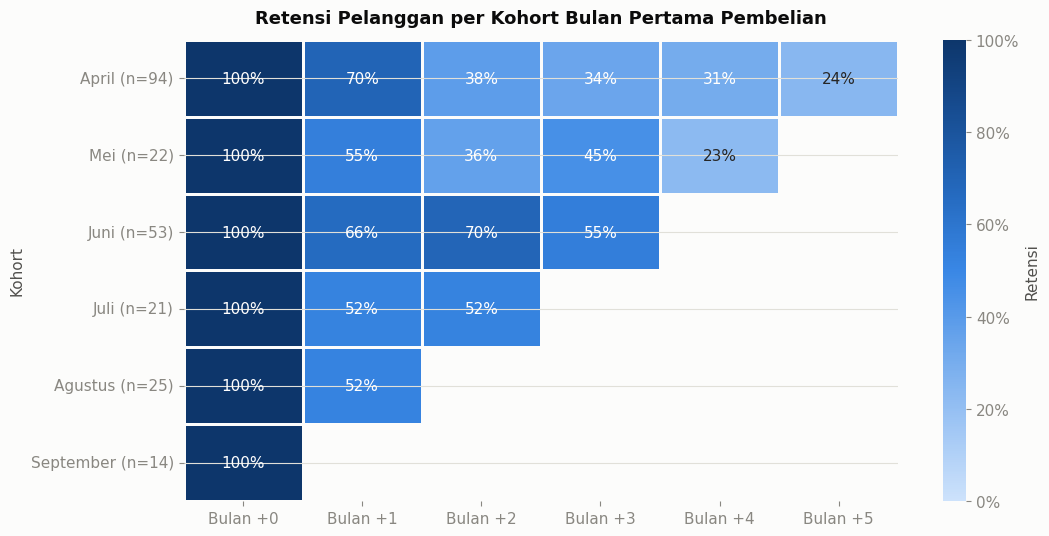

In [43]:
cohort = df[['NAMA', 'BULAN_NO']].drop_duplicates()
cohort['KOHORT'] = cohort['NAMA'].map(first_month)
cohort['UMUR'] = cohort['BULAN_NO'] - cohort['KOHORT']
ct = cohort.pivot_table(index='KOHORT', columns='UMUR', values='NAMA', aggfunc='nunique')
retensi = ct.div(ct[0], axis=0)
retensi.index = [f'{MONTH_ORDER[i]} (n={int(ct.loc[i, 0])})' for i in retensi.index]
retensi.columns = [f'Bulan +{c}' for c in retensi.columns]

fig, ax = plt.subplots(figsize=(11, 5.5))
sns.heatmap(retensi, cmap=SEQ_BLUE, annot=True, fmt='.0%', vmin=0, vmax=1, linewidths=2, linecolor=SURFACE,
            cbar_kws={'label': 'Retensi', 'format': PCT}, ax=ax)
ax.set_title('Retensi Pelanggan per Kohort Bulan Pertama Pembelian')
ax.set_xlabel('')
ax.set_ylabel('Kohort')
plt.tight_layout()
plt.show()

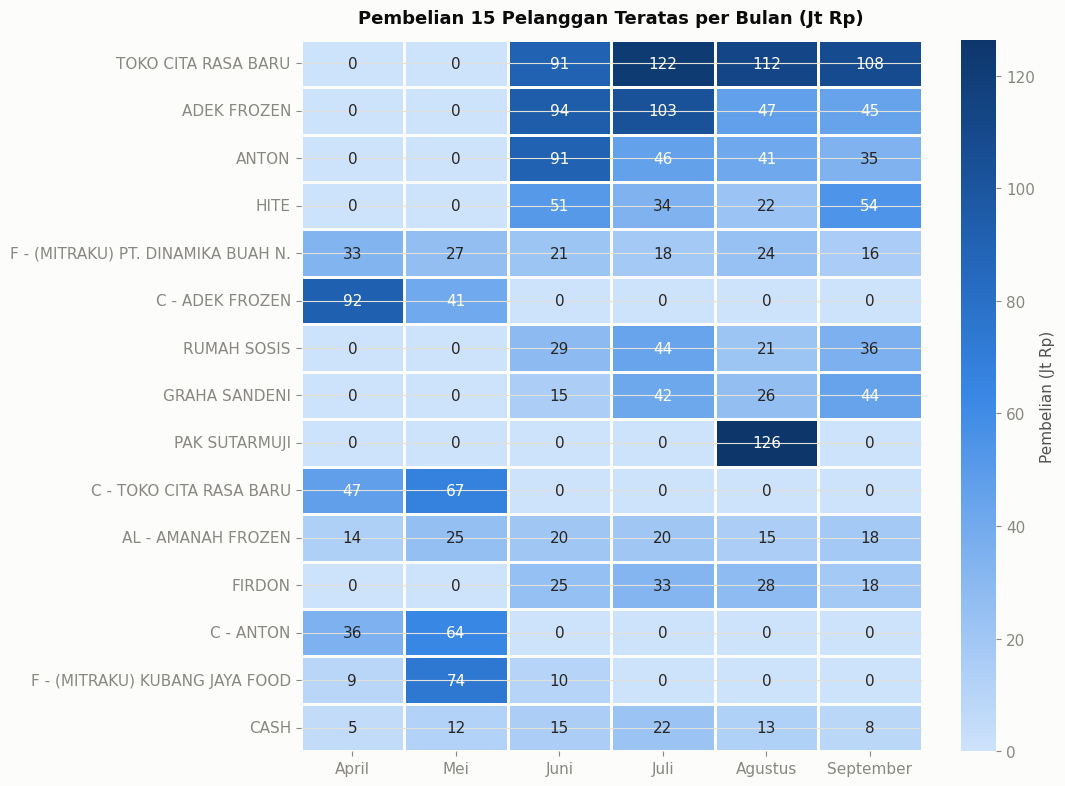

In [44]:
top15_cust = cust_rev.head(15).index
hc = (df[df['NAMA'].isin(top15_cust)]
        .pivot_table(index='NAMA', columns='BULAN', values='JUMLAH', aggfunc='sum', observed=False)
        .fillna(0).loc[top15_cust] / 1e6)
hc.index = [short(i, 40) for i in hc.index]

fig, ax = plt.subplots(figsize=(11, 8))
sns.heatmap(hc, cmap=SEQ_BLUE, annot=True, fmt=',.0f', linewidths=2, linecolor=SURFACE,
            cbar_kws={'label': 'Pembelian (Jt Rp)'}, ax=ax)
ax.set_title('Pembelian 15 Pelanggan Teratas per Bulan (Jt Rp)')
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

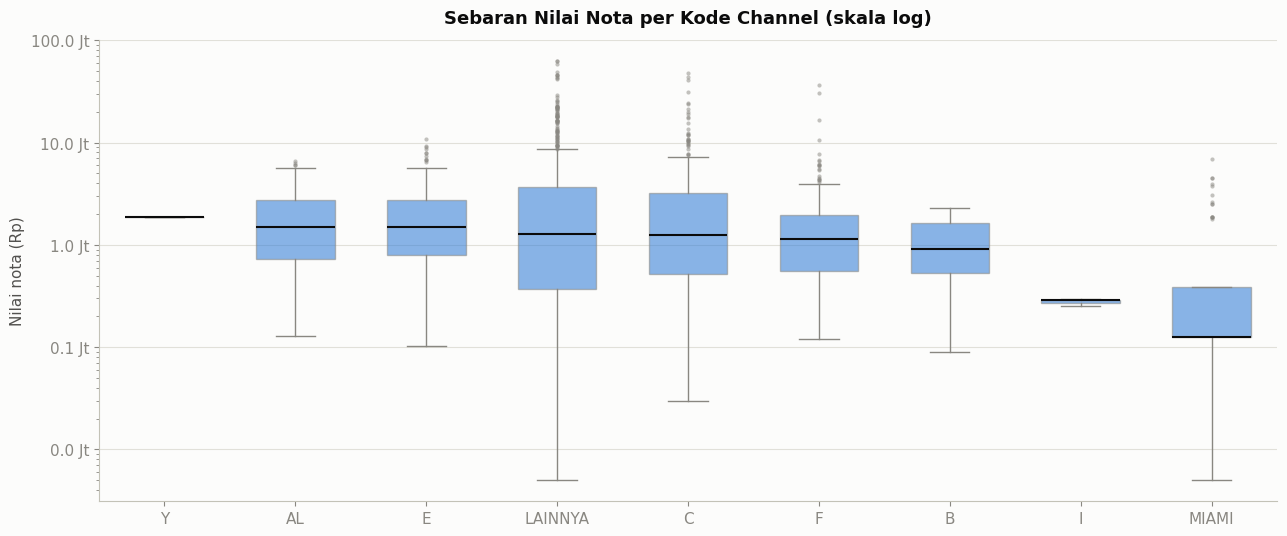

In [45]:
nota = df.groupby('NOTA').agg(NILAI=('JUMLAH', 'sum'), ITEM=('KODEBARA', 'size'),
                              BRAND=('BRAND', 'nunique'), CHANNEL=('CHANNEL', 'first'), BULAN=('BULAN', 'first'))
nota_pos = nota[nota['NILAI'] > 0]
ch_order = nota_pos.groupby('CHANNEL')['NILAI'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(13, 5.5))
styled_boxplot(ax, [nota_pos.loc[nota_pos['CHANNEL'] == c, 'NILAI'] for c in ch_order], list(ch_order))
ax.set_yscale('log')
ax.yaxis.set_major_formatter(RP_JT1)
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_title('Sebaran Nilai Nota per Kode Channel (skala log)')
ax.set_ylabel('Nilai nota (Rp)')
plt.tight_layout()
plt.show()

## 10. Analisis Nota (Keranjang Belanja)

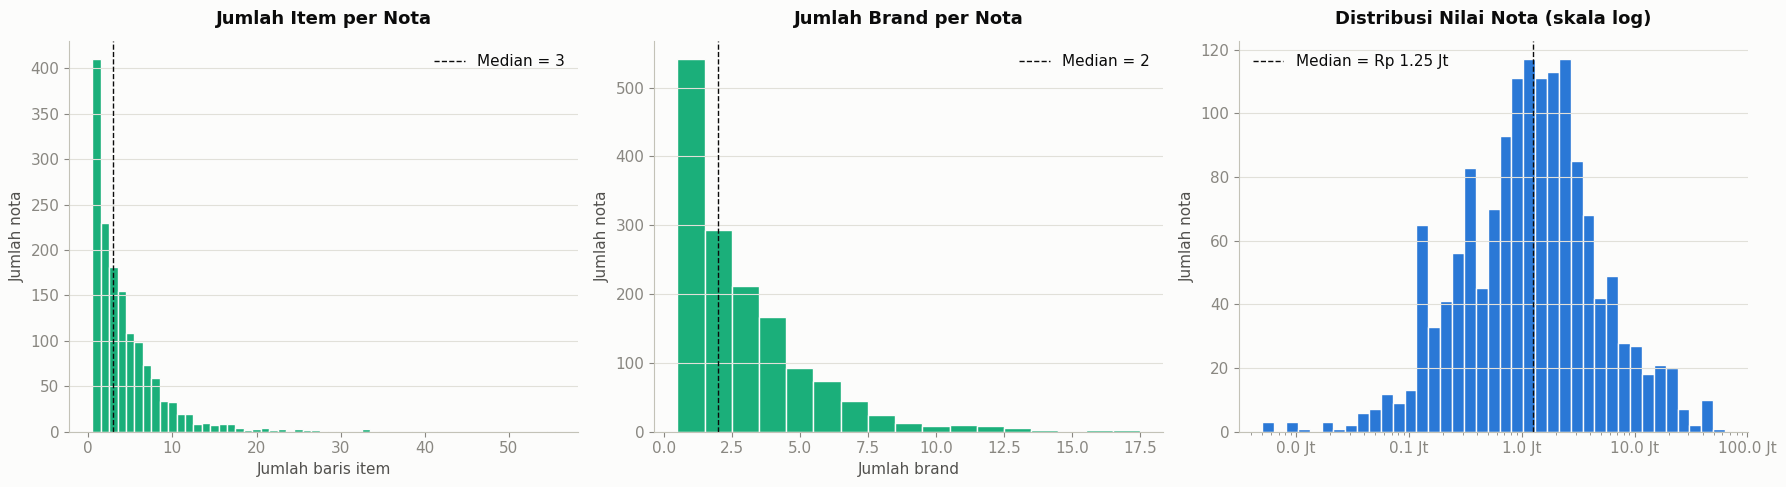

In [46]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
axes[0].hist(nota['ITEM'], bins=np.arange(1, nota['ITEM'].max() + 2) - 0.5, color=C_CNT, edgecolor=SURFACE)
axes[0].axvline(nota['ITEM'].median(), color=INK, linestyle='--', linewidth=1, label=f"Median = {nota['ITEM'].median():.0f}")
axes[0].set_title('Jumlah Item per Nota')
axes[0].set_xlabel('Jumlah baris item')
axes[0].legend()

axes[1].hist(nota['BRAND'], bins=np.arange(1, nota['BRAND'].max() + 2) - 0.5, color=C_CNT, edgecolor=SURFACE)
axes[1].axvline(nota['BRAND'].median(), color=INK, linestyle='--', linewidth=1, label=f"Median = {nota['BRAND'].median():.0f}")
axes[1].set_title('Jumlah Brand per Nota')
axes[1].set_xlabel('Jumlah brand')
axes[1].legend()

bins = np.logspace(np.log10(nota_pos['NILAI'].min()), np.log10(nota_pos['NILAI'].max()), 40)
axes[2].hist(nota_pos['NILAI'], bins=bins, color=C_RP, edgecolor=SURFACE)
axes[2].axvline(nota_pos['NILAI'].median(), color=INK, linestyle='--', linewidth=1,
                label=f"Median = Rp {nota_pos['NILAI'].median()/1e6:,.2f} Jt")
axes[2].set_xscale('log')
axes[2].xaxis.set_major_formatter(RP_JT1)
axes[2].xaxis.set_minor_formatter(mticker.NullFormatter())
axes[2].set_title('Distribusi Nilai Nota (skala log)')
axes[2].legend()
for ax in axes:
    ax.set_ylabel('Jumlah nota')
plt.tight_layout()
plt.show()

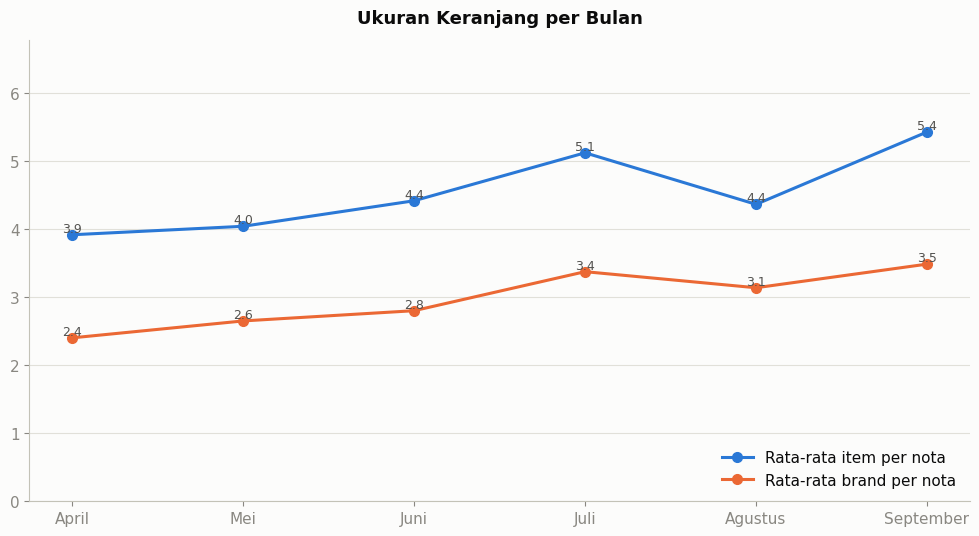

In [47]:
fig, ax = plt.subplots(figsize=(10, 5.5))
nb = nota.groupby('BULAN', observed=False)[['ITEM', 'BRAND']].mean()
x = np.arange(len(nb))
ax.plot(x, nb['ITEM'], color=CAT[0], linewidth=2.2, marker='o', markersize=7, label='Rata-rata item per nota')
ax.plot(x, nb['BRAND'], color=CAT[1], linewidth=2.2, marker='o', markersize=7, label='Rata-rata brand per nota')
for col in ['ITEM', 'BRAND']:
    for xi, v in zip(x, nb[col]):
        ax.text(xi, v, f'{v:.1f}', ha='center', va='bottom', fontsize=9, color=INK_SECOND, transform=ax.transData)
ax.set_xticks(x, MONTH_ORDER)
ax.set_ylim(0, nb.values.max() * 1.25)
ax.set_title('Ukuran Keranjang per Bulan')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

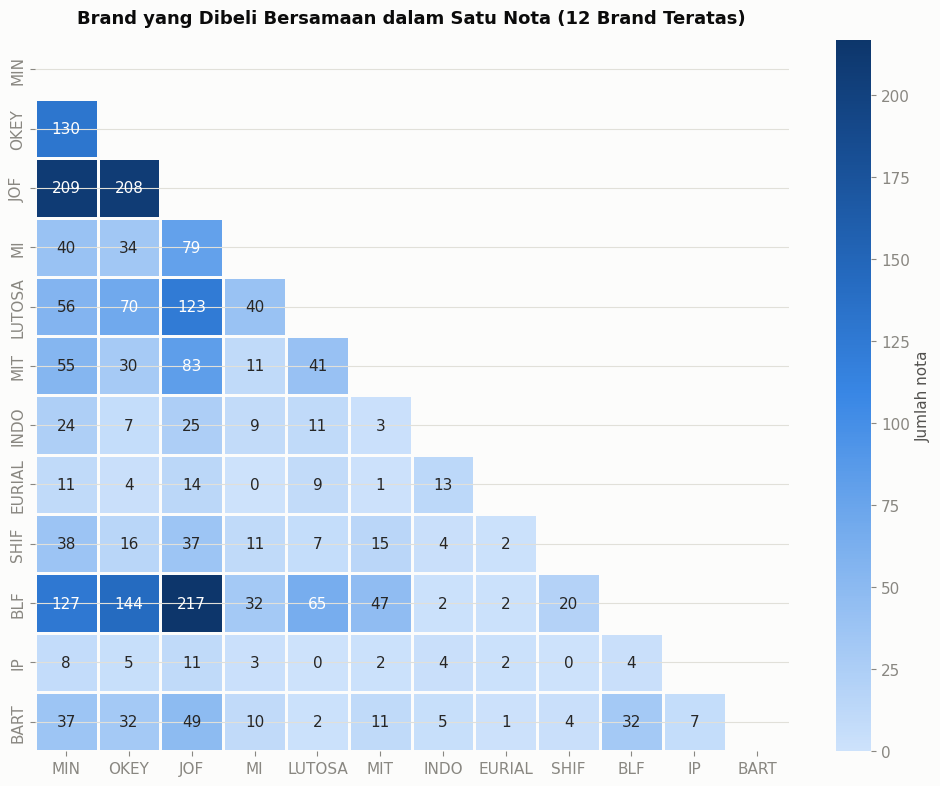

In [48]:
top_b = brand_rev.head(12).index
basket = pd.crosstab(df['NOTA'], df['BRAND'])[top_b].gt(0).astype(int)
co = basket.T @ basket
np.fill_diagonal(co.values, 0)
mask = np.triu(np.ones_like(co, dtype=bool))

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(co, mask=mask, cmap=SEQ_BLUE, annot=True, fmt='d', linewidths=2, linecolor=SURFACE,
            cbar_kws={'label': 'Jumlah nota'}, ax=ax)
ax.set_title('Brand yang Dibeli Bersamaan dalam Satu Nota (12 Brand Teratas)')
ax.set_xlabel('')
ax.set_ylabel('')
plt.tight_layout()
plt.show()

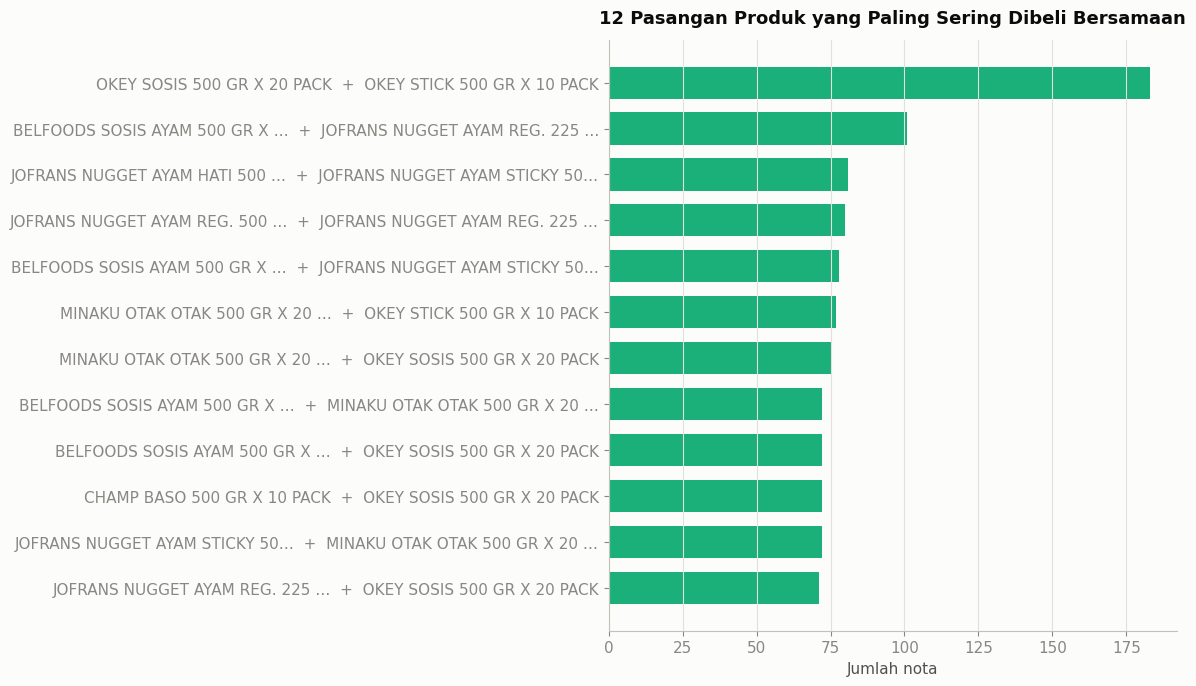

In [49]:
nama_produk = df.groupby('KODEBARA')['PRODUK'].first()
pair_counter = Counter()
for items in df.groupby('NOTA')['KODEBARA'].apply(lambda s: sorted(set(s))):
    pair_counter.update(combinations(items, 2))
top_pairs = pd.Series({f'{short(nama_produk[a], 30)}  +  {short(nama_produk[b], 30)}': n
                       for (a, b), n in pair_counter.most_common(12)})
barh_top(top_pairs, '12 Pasangan Produk yang Paling Sering Dibeli Bersamaan', 'Jumlah nota', C_CNT,
         figsize=(12, 7), label_len=70)

## 11. Harga, Satuan & Diskon

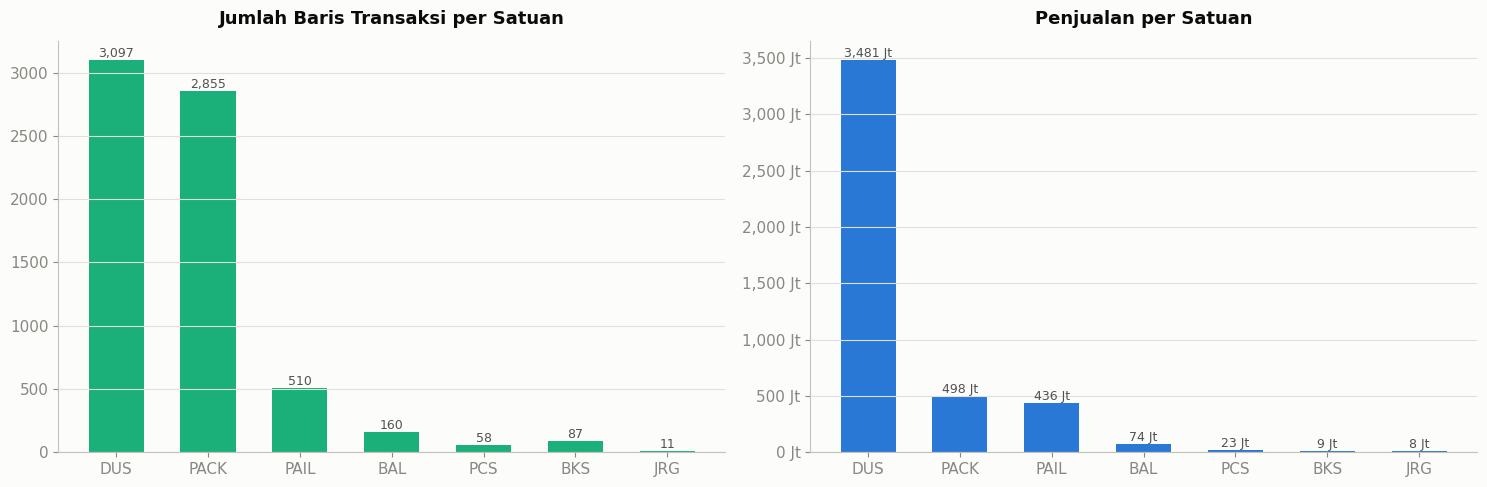

In [50]:
sat = df.groupby('SATUAN').agg(BARIS=('JUMLAH', 'size'), PENJUALAN=('JUMLAH', 'sum')).sort_values('PENJUALAN', ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
bars = axes[0].bar(sat.index, sat['BARIS'], color=C_CNT, width=0.6)
label_bars(axes[0], bars, lambda v: f'{v:,.0f}')
axes[0].set_title('Jumlah Baris Transaksi per Satuan')
bars = axes[1].bar(sat.index, sat['PENJUALAN'], color=C_RP, width=0.6)
label_bars(axes[1], bars, lambda v: f'{v/1e6:,.0f} Jt')
axes[1].yaxis.set_major_formatter(RP_JT)
axes[1].set_title('Penjualan per Satuan')
plt.tight_layout()
plt.show()

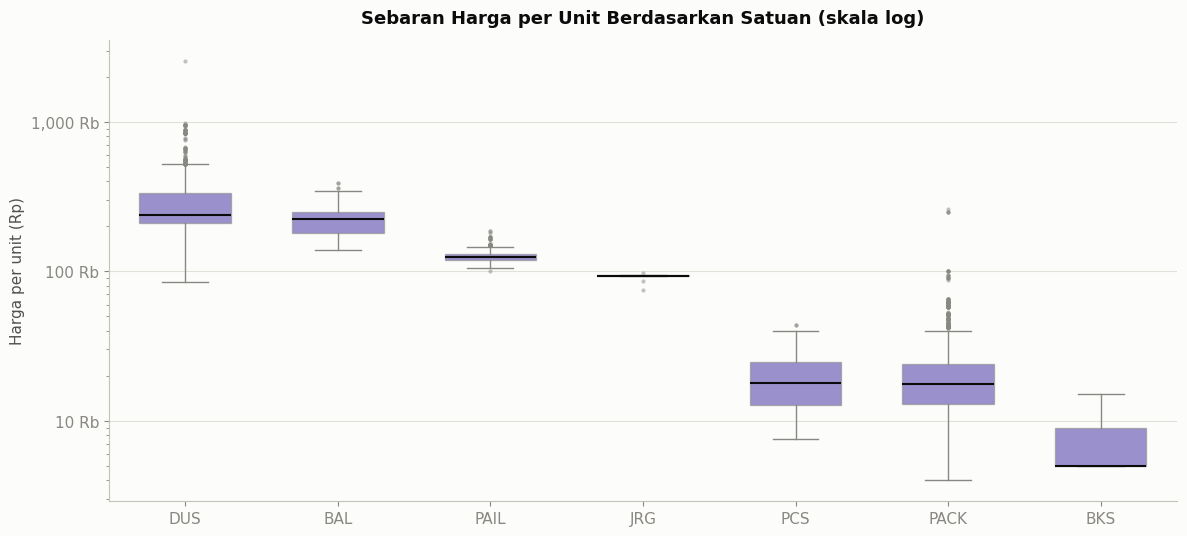

In [51]:
berbayar = df[~df['GRATIS']]
sat_order = berbayar.groupby('SATUAN')['HARGA'].median().sort_values(ascending=False).index

fig, ax = plt.subplots(figsize=(12, 5.5))
styled_boxplot(ax, [berbayar.loc[berbayar['SATUAN'] == s, 'HARGA'] for s in sat_order], list(sat_order), color=C_AVG)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(RP_RB)
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_title('Sebaran Harga per Unit Berdasarkan Satuan (skala log)')
ax.set_ylabel('Harga per unit (Rp)')
plt.tight_layout()
plt.show()

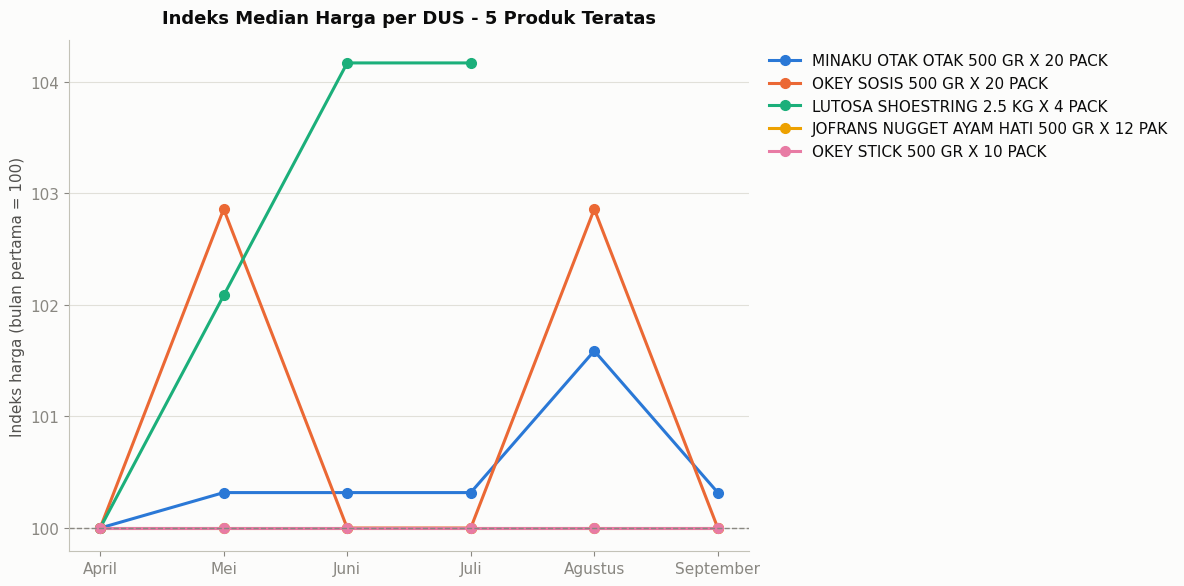

In [52]:
dus = df[(df['SATUAN'] == 'DUS') & (~df['GRATIS'])]
top5_dus = dus.groupby('PRODUK')['JUMLAH'].sum().nlargest(5).index.tolist()
med = (dus[dus['PRODUK'].isin(top5_dus)]
         .pivot_table(index='BULAN', columns='PRODUK', values='HARGA', aggfunc='median', observed=False)[top5_dus])
indeks = med / med.bfill().iloc[0] * 100

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(MONTH_ORDER))
for p, color in zip(top5_dus, CAT):
    ax.plot(x, indeks[p].values, color=color, linewidth=2.2, marker='o', markersize=7, label=short(p, 40))
ax.axhline(100, color=INK_MUTED, linestyle='--', linewidth=1)
ax.set_xticks(x, MONTH_ORDER)
ax.set_ylabel('Indeks harga (bulan pertama = 100)')
ax.set_title('Indeks Median Harga per DUS - 5 Produk Teratas')
ax.legend(loc='upper left', bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

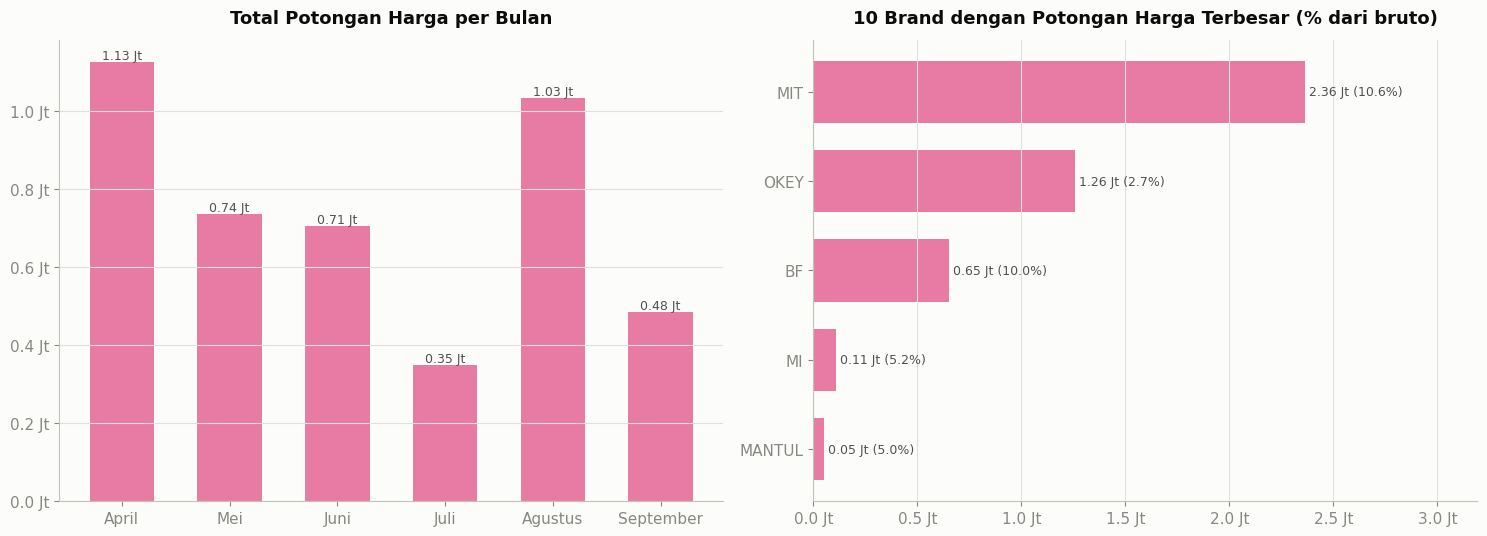

In [53]:
disk = df[df['DISKON'] > 0]
disk_bulan = df.groupby('BULAN', observed=False)['DISKON'].sum()
disk_brand = disk.groupby('BRAND')['DISKON'].sum().nlargest(10)
disk_pct = (disk.groupby('BRAND')['DISKON'].sum() / disk.groupby('BRAND')['BRUTO'].sum()).loc[disk_brand.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
bars = axes[0].bar(disk_bulan.index.astype(str), disk_bulan.values, color=C_DISC, width=0.6)
label_bars(axes[0], bars, lambda v: f'{v/1e6:,.2f} Jt')
axes[0].yaxis.set_major_formatter(RP_JT1)
axes[0].set_title('Total Potongan Harga per Bulan')
y = np.arange(len(disk_brand))
bars = axes[1].barh(y, disk_brand.values[::-1], color=C_DISC, height=0.7)
axes[1].set_yticks(y, disk_brand.index[::-1])
for b, p in zip(bars, disk_pct.values[::-1]):
    axes[1].text(b.get_width(), b.get_y() + b.get_height() / 2, f' {b.get_width()/1e6:,.2f} Jt ({p:.1%})',
                 va='center', fontsize=9, color=INK_SECOND)
axes[1].set_xlim(0, disk_brand.max() * 1.35)
axes[1].xaxis.set_major_formatter(RP_JT1)
xgrid(axes[1])
axes[1].set_title('10 Brand dengan Potongan Harga Terbesar (% dari bruto)')
plt.tight_layout()
plt.show()

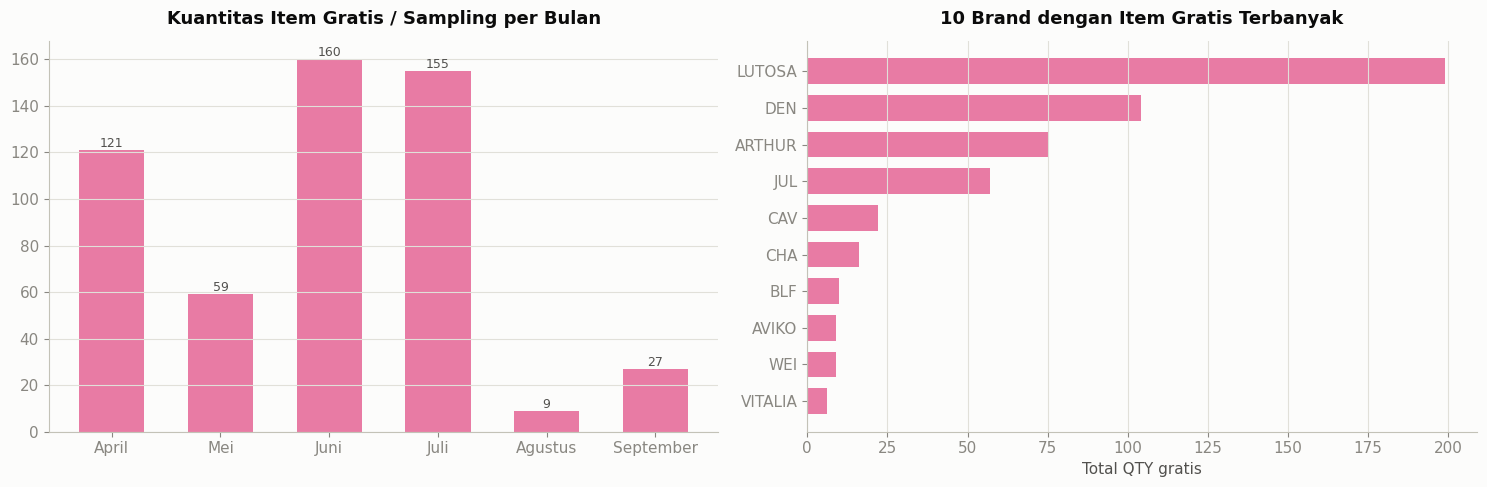

In [54]:
gratis = df[df['GRATIS']]
g_bulan = gratis.groupby('BULAN', observed=False)['QTY'].sum()
g_brand = gratis.groupby('BRAND')['QTY'].sum().nlargest(10)

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
bars = axes[0].bar(g_bulan.index.astype(str), g_bulan.values, color=C_DISC, width=0.6)
label_bars(axes[0], bars, lambda v: f'{v:,.0f}')
axes[0].set_title('Kuantitas Item Gratis / Sampling per Bulan')
barh_top(g_brand, '10 Brand dengan Item Gratis Terbanyak', 'Total QTY gratis', C_DISC, ax=axes[1])
plt.tight_layout()
plt.show()

## 12. Distribusi & Outlier

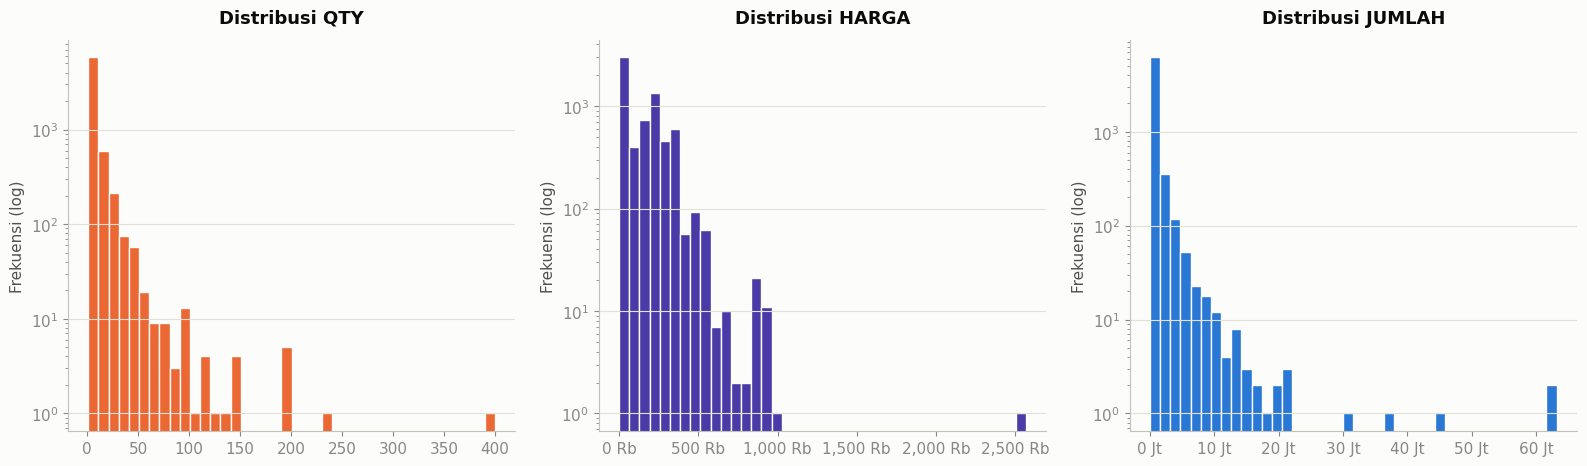

In [55]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
for ax, col, color in zip(axes, ['QTY', 'HARGA', 'JUMLAH'], [C_QTY, C_AVG, C_RP]):
    ax.hist(df[col], bins=40, color=color, edgecolor=SURFACE)
    ax.set_title(f'Distribusi {col}')
    ax.set_yscale('log')
    ax.set_ylabel('Frekuensi (log)')
axes[1].xaxis.set_major_formatter(RP_RB)
axes[2].xaxis.set_major_formatter(RP_JT)
plt.tight_layout()
plt.show()

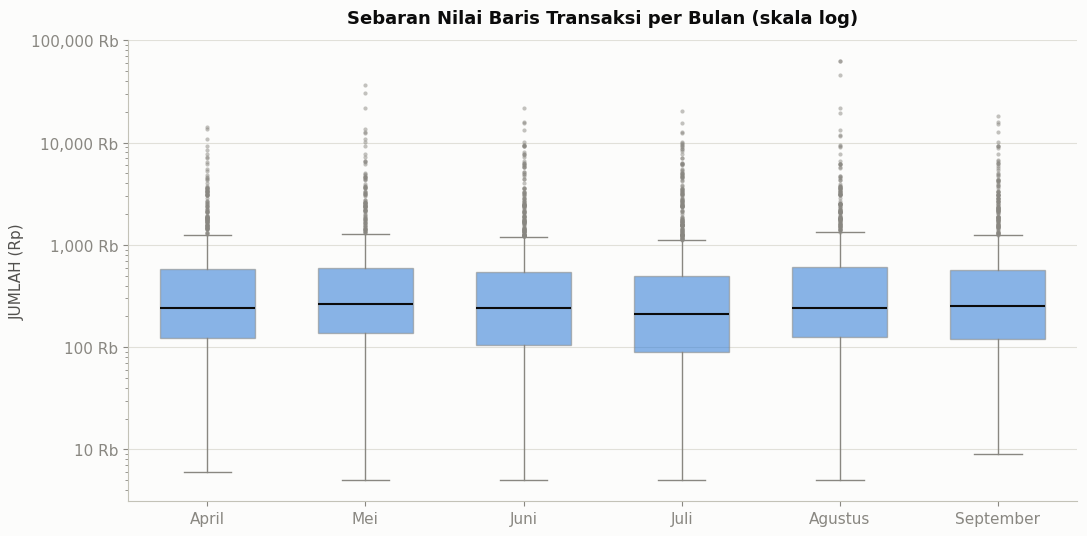

In [56]:
pos_rows = df[df['JUMLAH'] > 0]

fig, ax = plt.subplots(figsize=(11, 5.5))
styled_boxplot(ax, [pos_rows.loc[pos_rows['BULAN'] == m, 'JUMLAH'] for m in MONTH_ORDER], MONTH_ORDER)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(RP_RB)
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.set_title('Sebaran Nilai Baris Transaksi per Bulan (skala log)')
ax.set_ylabel('JUMLAH (Rp)')
plt.tight_layout()
plt.show()

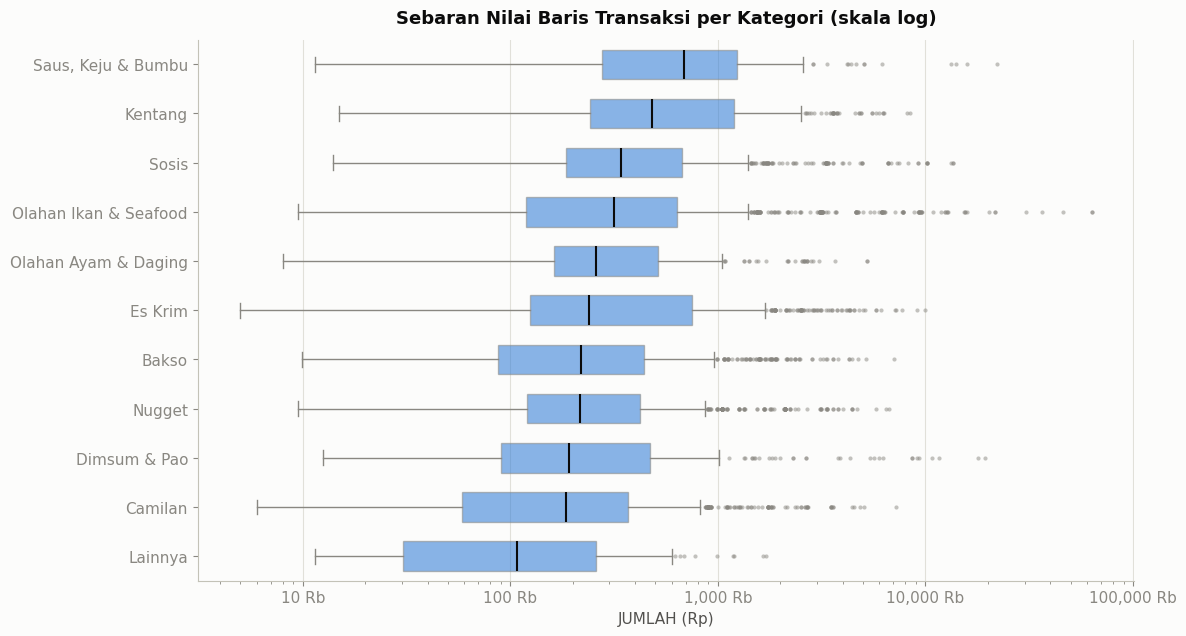

In [57]:
kat_order = pos_rows.groupby('KATEGORI')['JUMLAH'].median().sort_values().index

fig, ax = plt.subplots(figsize=(12, 6.5))
styled_boxplot(ax, [pos_rows.loc[pos_rows['KATEGORI'] == k, 'JUMLAH'] for k in kat_order], list(kat_order), horizontal=True)
ax.set_xscale('log')
ax.xaxis.set_major_formatter(RP_RB)
ax.xaxis.set_minor_formatter(mticker.NullFormatter())
xgrid(ax)
ax.set_title('Sebaran Nilai Baris Transaksi per Kategori (skala log)')
ax.set_xlabel('JUMLAH (Rp)')
plt.tight_layout()
plt.show()

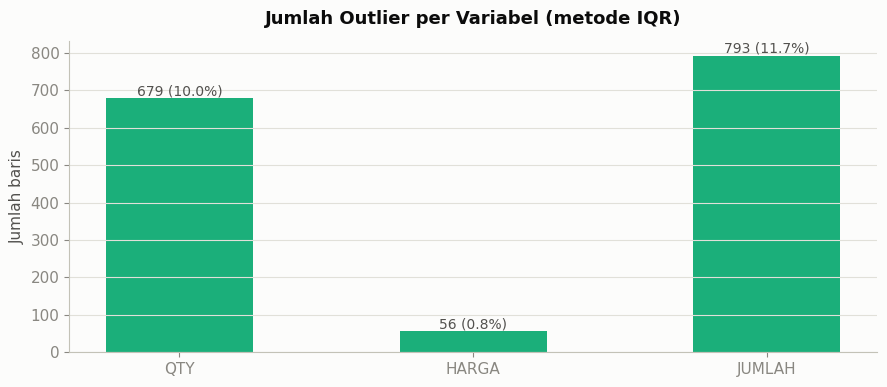

In [58]:
def iqr_outlier(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return ((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum()

out = pd.DataFrame({c: [iqr_outlier(df[c])] for c in ['QTY', 'HARGA', 'JUMLAH']}, index=['Outlier']).T
out['Persen'] = out['Outlier'] / len(df)

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(out.index, out['Outlier'], color=C_CNT, width=0.5)
for b, p in zip(bars, out['Persen']):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height(), f'{int(b.get_height()):,} ({p:.1%})',
            ha='center', va='bottom', fontsize=10, color=INK_SECOND)
ax.set_title('Jumlah Outlier per Variabel (metode IQR)')
ax.set_ylabel('Jumlah baris')
plt.tight_layout()
plt.show()

## 13. Korelasi & Hubungan Antar Variabel

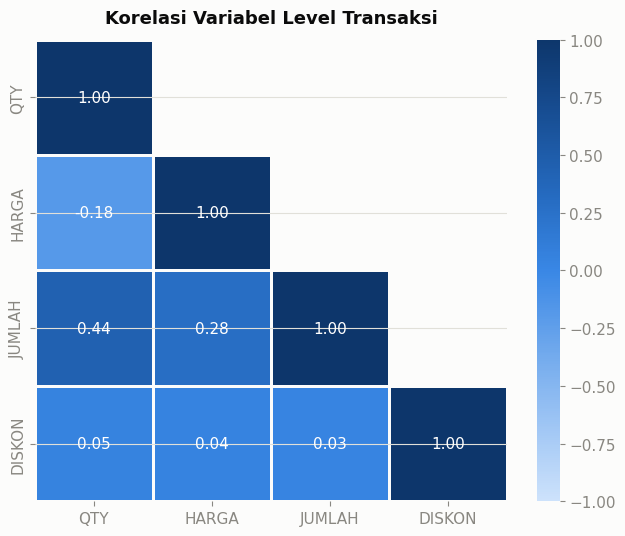

In [59]:
corr = df[['QTY', 'HARGA', 'JUMLAH', 'DISKON']].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
sns.heatmap(corr, cmap=SEQ_BLUE, annot=True, fmt='.2f', vmin=-1, vmax=1, linewidths=2, linecolor=SURFACE,
            mask=np.triu(np.ones_like(corr, dtype=bool), k=1), ax=ax)
ax.set_title('Korelasi Variabel Level Transaksi')
plt.tight_layout()
plt.show()

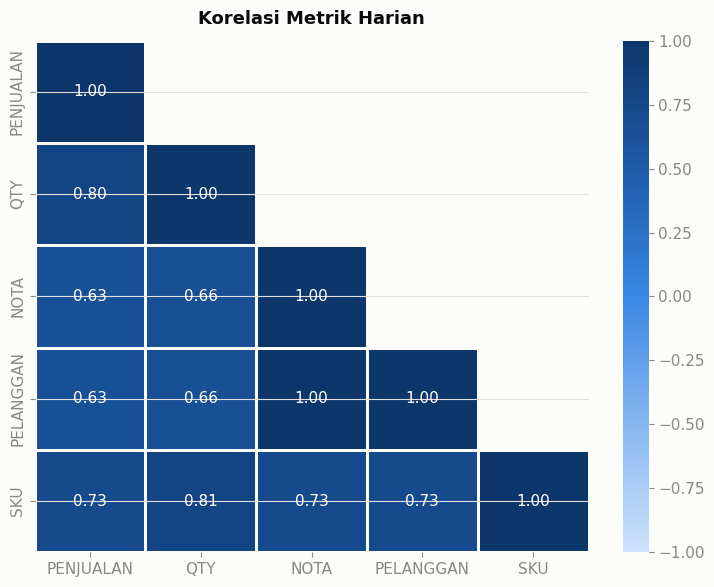

In [60]:
harian = df.groupby('TGL').agg(PENJUALAN=('JUMLAH', 'sum'), QTY=('QTY', 'sum'), NOTA=('NOTA', 'nunique'),
                               PELANGGAN=('NAMA', 'nunique'), SKU=('KODEBARA', 'nunique'))
corr_h = harian.corr()

fig, ax = plt.subplots(figsize=(7.5, 6))
sns.heatmap(corr_h, cmap=SEQ_BLUE, annot=True, fmt='.2f', vmin=-1, vmax=1, linewidths=2, linecolor=SURFACE,
            mask=np.triu(np.ones_like(corr_h, dtype=bool), k=1), ax=ax)
ax.set_title('Korelasi Metrik Harian')
plt.tight_layout()
plt.show()

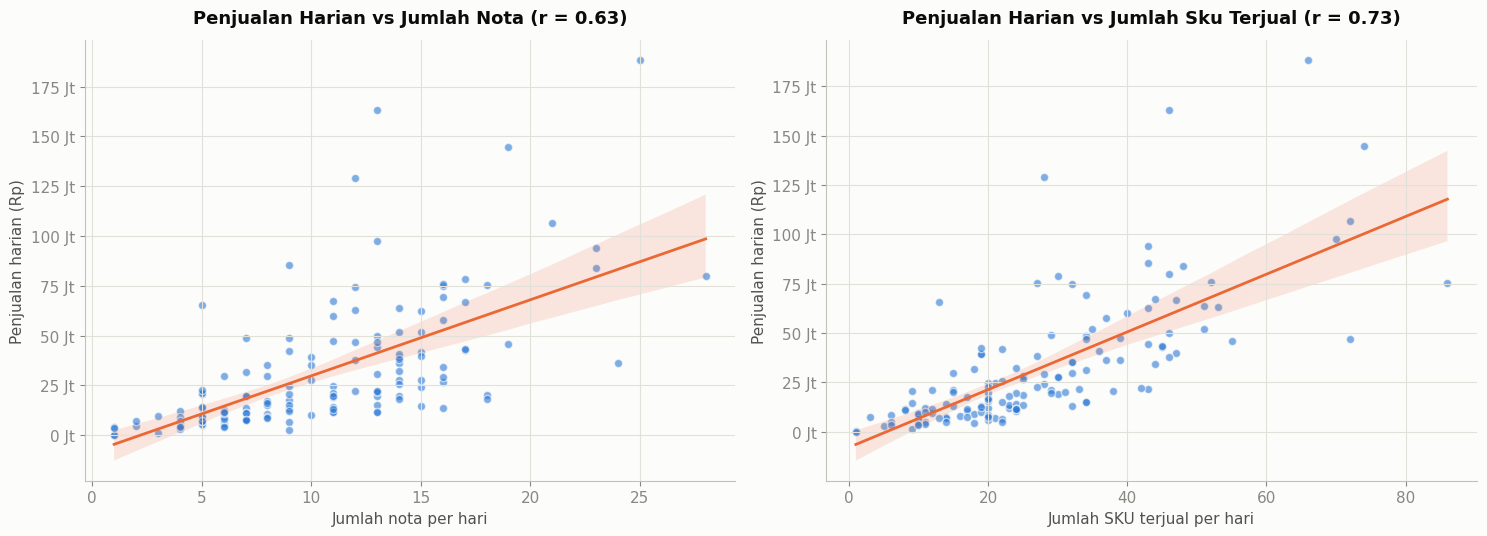

In [61]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
for ax, col, xlabel in zip(axes, ['NOTA', 'SKU'], ['Jumlah nota per hari', 'Jumlah SKU terjual per hari']):
    sns.regplot(data=harian, x=col, y='PENJUALAN', ax=ax,
                scatter_kws=dict(s=35, alpha=0.6, color=C_RP, edgecolor=SURFACE),
                line_kws=dict(color=CAT[1], linewidth=2))
    r = harian[[col, 'PENJUALAN']].corr().iloc[0, 1]
    ax.set_title(f'Penjualan Harian vs {xlabel.split(" per")[0].title()} (r = {r:.2f})')
    ax.set_xlabel(xlabel)
    ax.set_ylabel('Penjualan harian (Rp)')
    ax.yaxis.set_major_formatter(RP_JT)
    ax.grid(axis='x', visible=True)
plt.tight_layout()
plt.show()

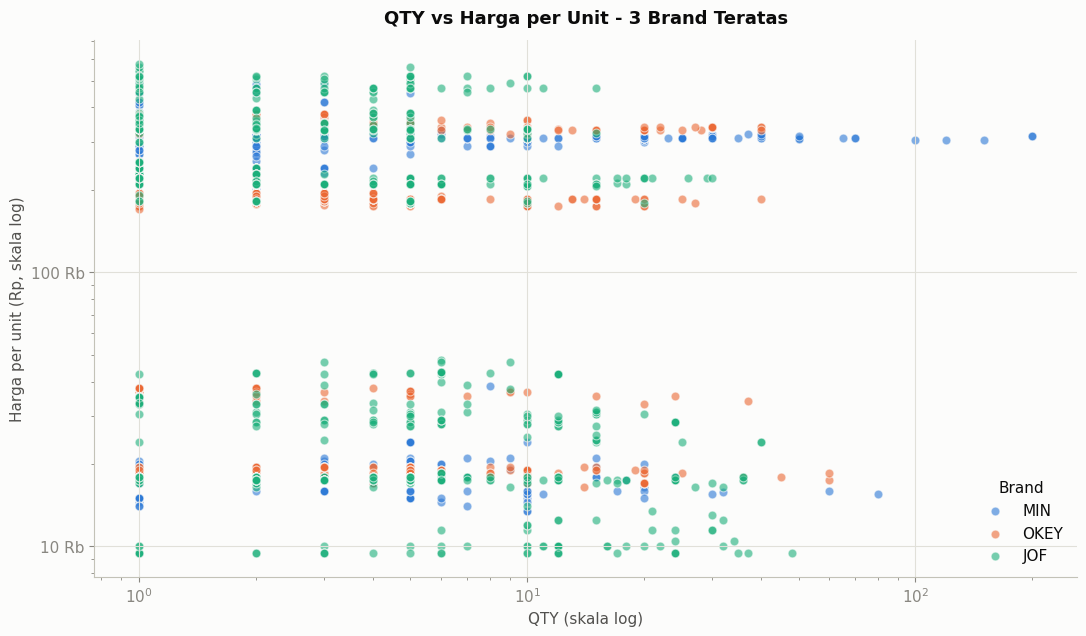

In [62]:
top3_brand = brand_rev.head(3).index

fig, ax = plt.subplots(figsize=(11, 6.5))
for b, color in zip(top3_brand, CAT):
    sub = df[(df['BRAND'] == b) & (df['HARGA'] > 0)]
    ax.scatter(sub['QTY'], sub['HARGA'], s=40, alpha=0.6, color=color, label=b, edgecolor=SURFACE, linewidth=0.8)
ax.set_xscale('log')
ax.set_yscale('log')
ax.yaxis.set_major_formatter(RP_RB)
ax.yaxis.set_minor_formatter(mticker.NullFormatter())
ax.grid(axis='x', visible=True)
ax.set_xlabel('QTY (skala log)')
ax.set_ylabel('Harga per unit (Rp, skala log)')
ax.set_title('QTY vs Harga per Unit - 3 Brand Teratas')
ax.legend(title='Brand')
plt.tight_layout()
plt.show()